In [1]:
import dlib

from pathlib import Path
import pickle
import time

# Data, image processing and models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import (
    GroupKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
)
from src.preprocess import preprocess_kdef_image
from sklearn.feature_selection import mutual_info_classif, SelectKBest, f_classif


# Task 1

## Part 1
Load the data and split it in training,validation and testing sets

In [3]:
df = pd.read_csv("./data/fer2013.csv")

print( df['Usage'].value_counts() )


Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


In [5]:
# We use for training and validation the "Training" and "PublicTest"
trai_df = df[df['Usage']== 'Training'].copy()
vali_df = df[df['Usage'] == 'PublicTest'].copy()
test_df = df[df['Usage'] == 'PrivateTest'].copy() 

# Storing train and test data frames
trai_df.to_csv("./data/fer2013_train.csv", encoding='utf-8', index=False)
vali_df.to_csv("./data/fer2013_validation.csv", encoding='utf-8', index=False)
test_df.to_csv("./data/fer2013_test.csv", encoding='utf-8', index=False)


## Part 2
statistics and labelling

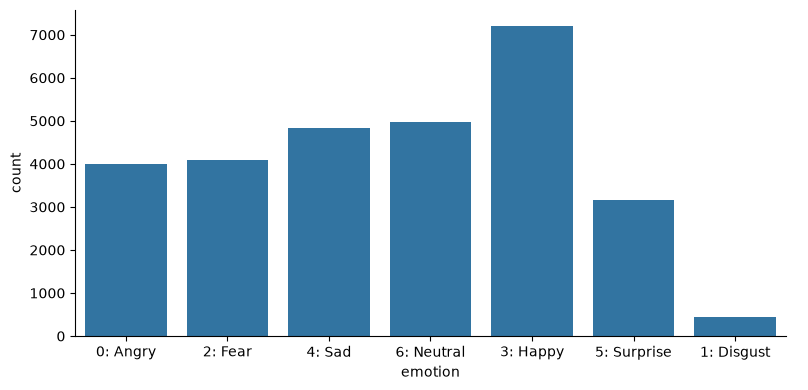

In [6]:
emotionDict = {
    0:'0: Angry',
    1:'1: Disgust',
    2:'2: Fear',
    3:'3: Happy',
    4:'4: Sad',
    5:'5: Surprise',
    6:'6: Neutral'
}


sns.catplot(data=trai_df.replace({'emotion': emotionDict}), kind='count', x='emotion', height=4, aspect=2)

plt.show()


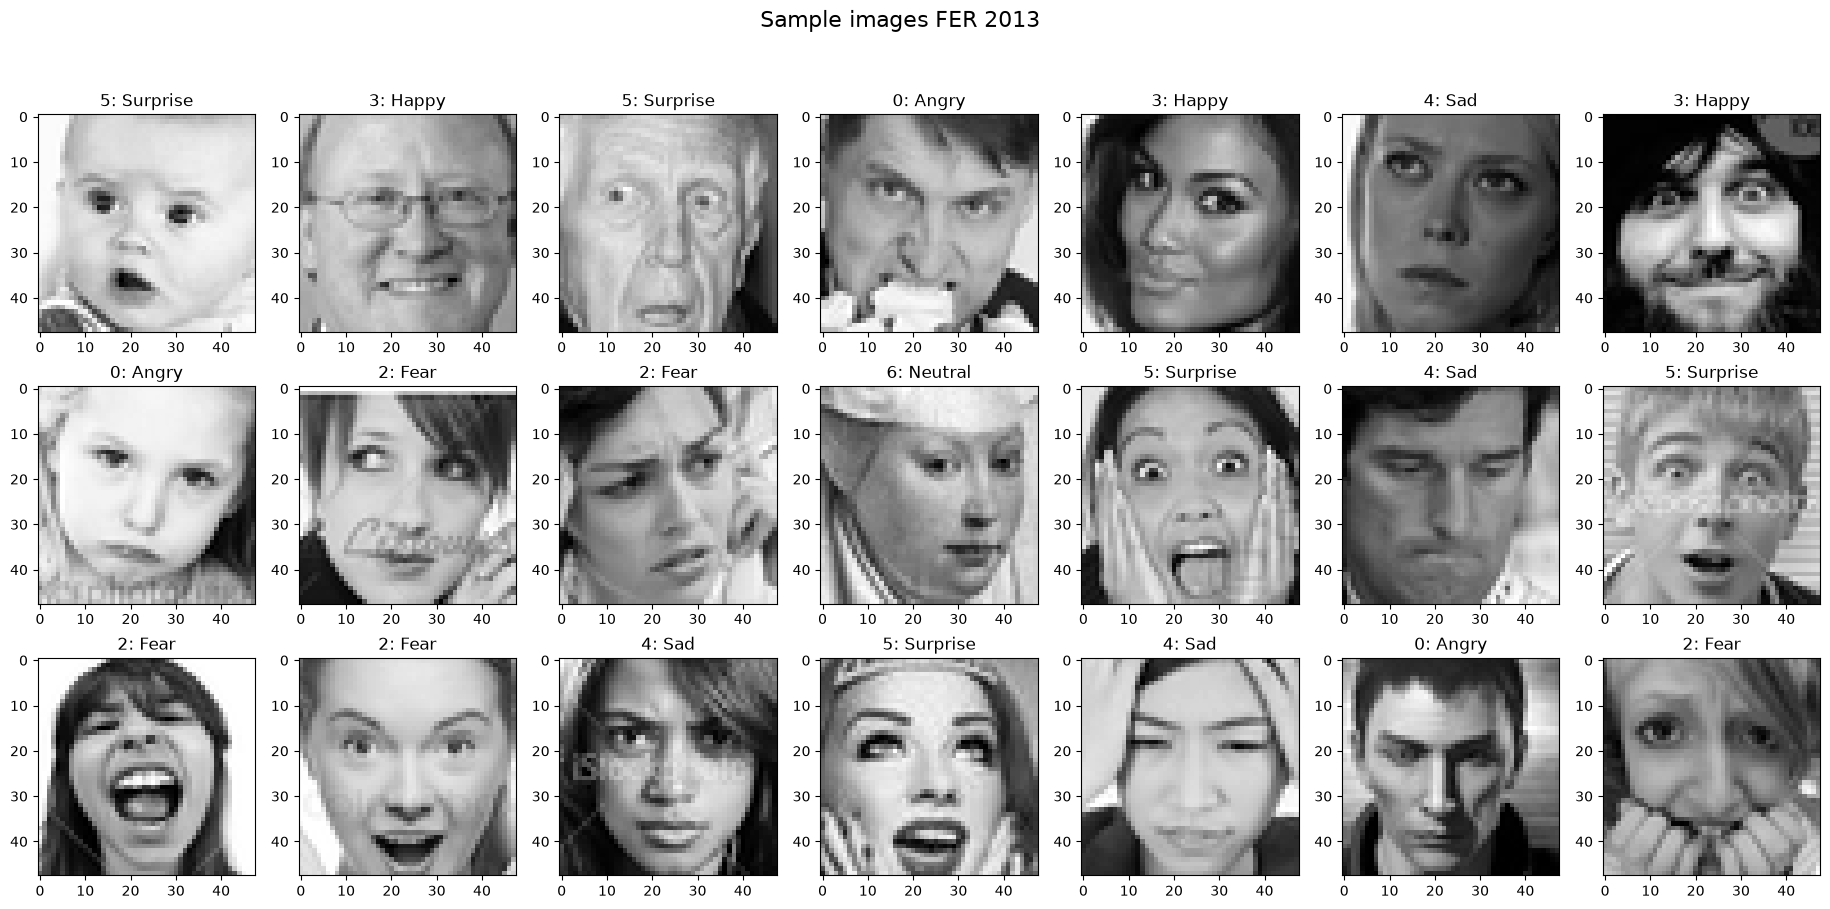

In [7]:
# Now making some plots
random_rows = df.sample(n=21, random_state=43)
imgs = [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in random_rows['pixels']]
lbl =  random_rows['emotion'].values

fig, axes = plt.subplots(nrows=3, ncols=7, figsize=(23, 10))
fig.suptitle('Sample images FER 2013', fontsize=16)

# Loop through each subplot and customize
for i in range(7):
    for j in range(3):
        ax = axes[j, i]
        ax.imshow(imgs[j*7+i], cmap="gray") 
        ax.set_title('%s'%(emotionDict[lbl[j*7+i]]))
        #ax.grid(True)
plt.show()


Compyting the class weights for the training test

In [8]:
csv_file = './data/fer2013_train.csv'
model_file = "./models/rf_fer_model_landmarks.pkl"


## Loading the Data

In [9]:
trai_df = pd.read_csv(csv_file)

# Computing class weights for unbalanced dataset
labelsTrain = trai_df['emotion'].values
cw = compute_class_weight(
    class_weight="balanced", classes=np.unique(labelsTrain), y=labelsTrain)
#class_weights = {0:cw[0],1:cw[1],2:cw[2], 3:cw[3], 4:cw[4], 5:cw[5], 6:cw[6]}


## Feature extraction pipeline

In [10]:
# Importing dlib's landmark detector
# Dlib landmarks from: 
#   https://github.com/davisking/dlib-models/blob/master/shape_predictor_68_face_landmarks.dat.bz2
landmDet = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")


def extractLandmarksFER(images):
    face_rects = dlib.rectangle(left=1, top=1, right=47, bottom=47)
    x1 = face_rects.left() 
    y1 = face_rects.top() 
    x2 = face_rects.right() 
    y2 = face_rects.bottom()

    landm = []
    for img in images:
        la = landmDet(img.astype(np.uint8), face_rects)

        # This works better if the standard scaler is not usec
        la2 = np.asarray( np.matrix([
            [
                (p.x-0.5*(x2-x1))/(x2-x1), (p.y-0.5*(y2-y1))/(y2-y1)
            ] for p in la.parts()])).astype(np.float32)
        la2 -= np.mean(la2, axis=0, keepdims=True)
        la2 /= np.max(np.abs(la2), axis=0, keepdims=True)

        landm.append(la2.flatten())
    feats = np.stack(landm)
    return(feats)

# Loading the images
images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in trai_df['pixels']])
feats = extractLandmarksFER(images)

images = None


## Evaluating the results

Random Forest + Landmarks

In [11]:
rf = RandomForestClassifier(
    n_estimators=300,       # Number of trees
    max_depth=11,           # Allow trees to grow fully
    max_features='sqrt',   # Use sqrt(features) for splitting
    random_state=42,
    n_jobs=-1,             # Use all available CPU cores 
    #class_weight= "balanced", #class_weights,
    criterion="entropy",
)


rf.fit(feats, trai_df['emotion'].values)

joblib.dump(rf, model_file)
print(f"Model saved to {model_file}")


Model saved to ./models/rf_fer_model_landmarks.pkl


Perform to validation test and Confusion Matrix Random Forest + Landmarks

Accuracy: 0.48
Balanced accuracy: 0.41
Macro F1: 0.41


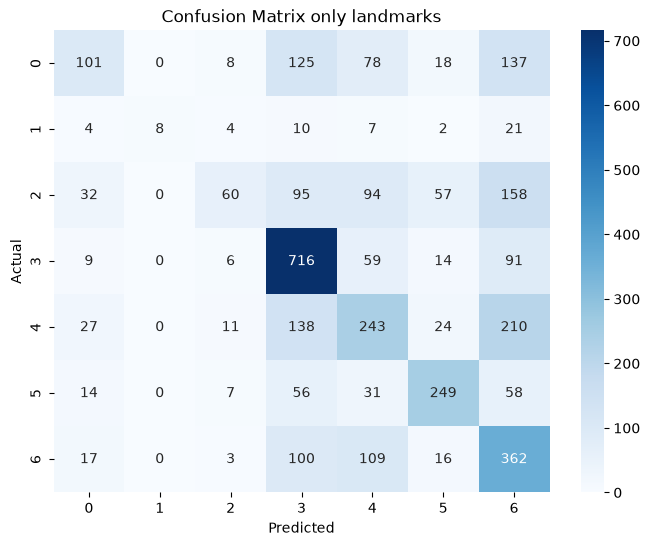

In [12]:
def preprocessingFer(dataFrame):
    # Convert pixel strings to 48x48 images
    images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in dataFrame['pixels']])
    X =  extractLandmarksFER(images)
    y = dataFrame['emotion'].values
    return([X,y])


# Predict and evaluate
valid = pd.read_csv('./data/fer2013_validation.csv')
X_valid, y_valid = preprocessingFer(valid)

y_pred = rf.predict(X_valid)
accuracy = accuracy_score(y_valid, y_pred)
conf_matrix = confusion_matrix(y_valid, y_pred)

baccuracy = balanced_accuracy_score(y_valid, y_pred)
macro_f1 = f1_score(y_valid, y_pred, average='macro')


# Print results
print(f"Accuracy: {accuracy:.2f}")
print(f"Balanced accuracy: {baccuracy:.2f}")
print(f"Macro F1: {macro_f1:.2f}")


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix only landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Logistic Regression + Landmarks

In [13]:
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(feats, labelsTrain)

print("Logistic Regression trained successfully")


Logistic Regression trained successfully


Evaluate Logistic Regression + Landmarks on the Validation Set

In [14]:
y_pred_lr = lr.predict(X_valid)

accuracy_lr = accuracy_score(y_valid, y_pred_lr)
baccuracy_lr = balanced_accuracy_score(y_valid, y_pred_lr)
macro_f1_lr = f1_score(y_valid, y_pred_lr, average='macro')

conf_matrix_lr = confusion_matrix(y_valid, y_pred_lr)

print(f"Accuracy: {accuracy_lr:.2f}")
print(f"Balanced accuracy: {baccuracy_lr:.2f}")
print(f"Macro F1: {macro_f1_lr:.2f}")


Accuracy: 0.48
Balanced accuracy: 0.39
Macro F1: 0.37


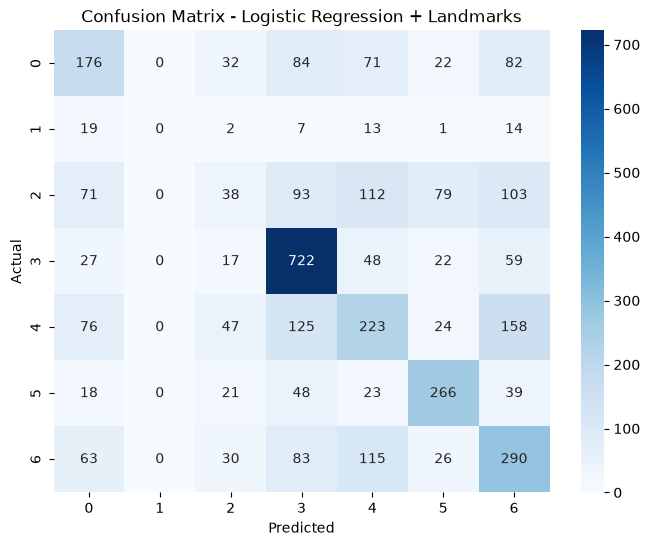

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + Landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + Landmarks

In [16]:
svm = SVC(
    kernel='rbf',
    random_state=42
)

svm.fit(feats, labelsTrain)

print("SVM trained successfully")


SVM trained successfully


Validation

In [17]:
# Evaluate SVM on the Validation Set

y_pred_svm = svm.predict(X_valid)

accuracy_svm = accuracy_score(y_valid, y_pred_svm)
baccuracy_svm = balanced_accuracy_score(y_valid, y_pred_svm)
macro_f1_svm = f1_score(y_valid, y_pred_svm, average='macro')

conf_matrix_svm = confusion_matrix(y_valid, y_pred_svm)

print(f"Accuracy: {accuracy_svm:.2f}")
print(f"Balanced accuracy: {baccuracy_svm:.2f}")
print(f"Macro F1: {macro_f1_svm:.2f}")


Accuracy: 0.46
Balanced accuracy: 0.37
Macro F1: 0.35


Confusion Matrix

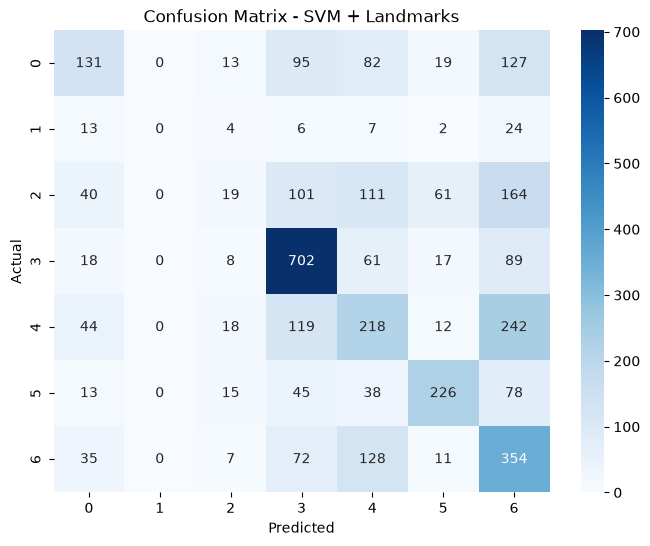

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + Landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## HOG Feature extraction

In [19]:
def extractHOG(images):
    hog_features = []

    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
        hog_features.append(features)

    return np.array(hog_features)


Extract training features

In [20]:
##Extract HOG features from the training images

images_train = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in trai_df['pixels']]
)

hog_feats = extractHOG(images_train)

images_train = None

print("HOG feature shape:", hog_feats.shape)


HOG feature shape: (28709, 900)


Random Forest + HOG

In [21]:
# Random Forest + HOG

rf_hog = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_hog.fit(hog_feats, labelsTrain)

print("Random Forest + HOG trained successfully")


Random Forest + HOG trained successfully


Validation Random Forest + HOG

In [22]:
images_valid = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in valid['pixels']]
)

hog_valid = extractHOG(images_valid)

images_valid = None

y_pred_rf_hog = rf_hog.predict(hog_valid)

accuracy_rf_hog = accuracy_score(y_valid, y_pred_rf_hog)
baccuracy_rf_hog = balanced_accuracy_score(y_valid, y_pred_rf_hog)
macro_f1_rf_hog = f1_score(y_valid, y_pred_rf_hog, average='macro')

conf_matrix_rf_hog = confusion_matrix(y_valid, y_pred_rf_hog)

print(f"Accuracy: {accuracy_rf_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_rf_hog:.2f}")
print(f"Macro F1: {macro_f1_rf_hog:.2f}")


Accuracy: 0.45
Balanced accuracy: 0.38
Macro F1: 0.39


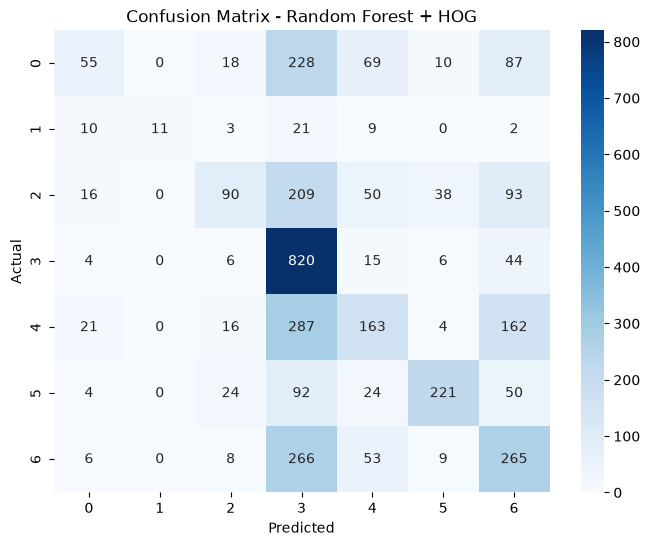

In [23]:
## Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Logistic Regression + HOG

Scaling

In [24]:
scaler_hog = StandardScaler()

hog_feats_scaled = scaler_hog.fit_transform(hog_feats)

print("Scaled HOG shape:", hog_feats_scaled.shape)


Scaled HOG shape: (28709, 900)


In [25]:
lr_hog = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_hog.fit(hog_feats_scaled, labelsTrain)

print("Logistic Regression + HOG trained successfully")


Logistic Regression + HOG trained successfully


Validation Test Logistic Regression + HOG

In [26]:
hog_valid_scaled = scaler_hog.transform(hog_valid)

y_pred_lr_hog = lr_hog.predict(hog_valid_scaled)

accuracy_lr_hog = accuracy_score(y_valid, y_pred_lr_hog)
baccuracy_lr_hog = balanced_accuracy_score(y_valid, y_pred_lr_hog)
macro_f1_lr_hog = f1_score(y_valid, y_pred_lr_hog, average='macro')

conf_matrix_lr_hog = confusion_matrix(y_valid, y_pred_lr_hog)

print(f"Accuracy: {accuracy_lr_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_lr_hog:.2f}")
print(f"Macro F1: {macro_f1_lr_hog:.2f}")


Accuracy: 0.43
Balanced accuracy: 0.40
Macro F1: 0.40


Confusion Matrix Logistic Regression + HOG

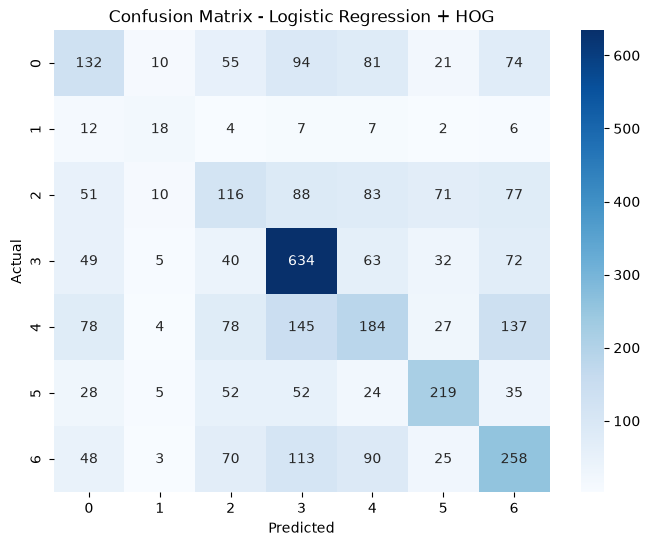

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + HOG

In [28]:
svm_hog = SVC(
    kernel='rbf',
    random_state=42
)

svm_hog.fit(hog_feats, labelsTrain)

print("SVM + HOG trained successfully")


SVM + HOG trained successfully


Validation Test SVM + HOG

In [29]:
y_pred_svm_hog = svm_hog.predict(hog_valid)

accuracy_svm_hog = accuracy_score(y_valid, y_pred_svm_hog)
baccuracy_svm_hog = balanced_accuracy_score(y_valid, y_pred_svm_hog)
macro_f1_svm_hog = f1_score(y_valid, y_pred_svm_hog, average='macro')

conf_matrix_svm_hog = confusion_matrix(y_valid, y_pred_svm_hog)

print(f"Accuracy: {accuracy_svm_hog:.2f}")
print(f"Balanced accuracy: {baccuracy_svm_hog:.2f}")
print(f"Macro F1: {macro_f1_svm_hog:.2f}")


Accuracy: 0.54
Balanced accuracy: 0.47
Macro F1: 0.50


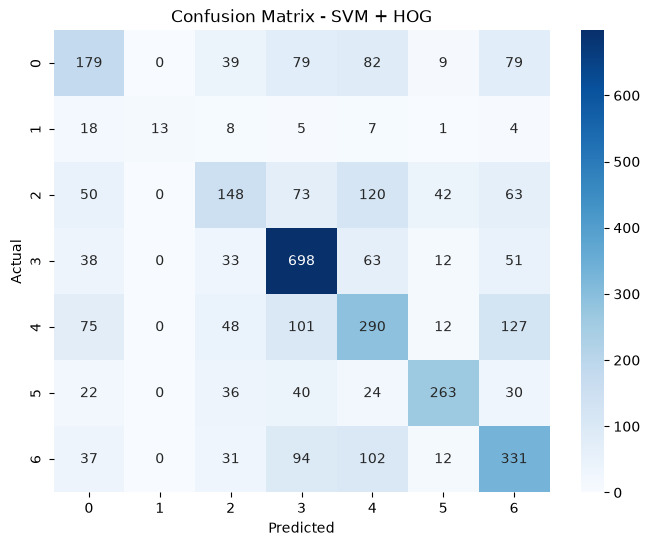

In [30]:
##Confusion Matrix

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm_hog, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + HOG")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## PCA

In [31]:
# Prepare training images as flattened pixel vectors

images_train = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in trai_df['pixels']]
)

X_pixels_train = images_train.reshape(len(images_train), -1)

images_train = None

print("Original feature shape:", X_pixels_train.shape)


Original feature shape: (28709, 2304)


In [32]:
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_pca_train = pca.fit_transform(X_pixels_train)

print("PCA feature shape:", X_pca_train.shape)
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.2f}")


PCA feature shape: (28709, 253)
Explained variance: 0.95


Scaling

In [33]:
scaler_pca = StandardScaler()

X_pca_train_scaled = scaler_pca.fit_transform(X_pca_train)


Logistic Regression + PCA

In [34]:
lr_pca = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_pca.fit(X_pca_train_scaled, labelsTrain)

print("Logistic Regression + PCA trained successfully")


Logistic Regression + PCA trained successfully


Evaluate Logistic Regression + PCA on the Validation Set

In [35]:
images_valid = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48)
     for pixels in valid['pixels']]
)

X_pixels_valid = images_valid.reshape(len(images_valid), -1)

images_valid = None

# Apply the already-fitted PCA
X_pca_valid = pca.transform(X_pixels_valid)

# Apply the already-fitted scaler
X_pca_valid_scaled = scaler_pca.transform(X_pca_valid)

y_pred_lr_pca = lr_pca.predict(X_pca_valid_scaled)

accuracy_lr_pca = accuracy_score(y_valid, y_pred_lr_pca)
baccuracy_lr_pca = balanced_accuracy_score(y_valid, y_pred_lr_pca)
macro_f1_lr_pca = f1_score(y_valid, y_pred_lr_pca, average='macro')

conf_matrix_lr_pca = confusion_matrix(y_valid, y_pred_lr_pca)

print(f"Accuracy: {accuracy_lr_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_lr_pca:.2f}")
print(f"Macro F1: {macro_f1_lr_pca:.2f}")


Accuracy: 0.38
Balanced accuracy: 0.30
Macro F1: 0.29


Confusion Matrix - Logistic Regression + PCA

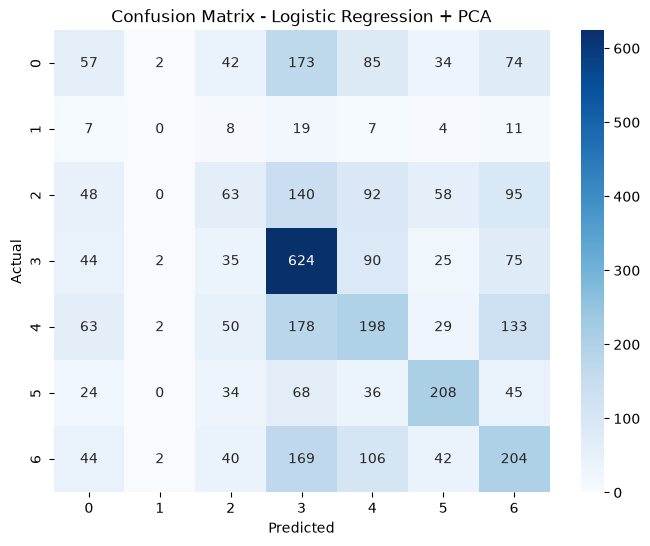

In [36]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_lr_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Random Forest + PCA

In [37]:
rf_pca = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_pca.fit(X_pca_train, labelsTrain)

print("Random Forest + PCA trained successfully")


Random Forest + PCA trained successfully


Evaluate Random Forest + PCA in the validation test

In [38]:
y_pred_rf_pca = rf_pca.predict(X_pca_valid)

accuracy_rf_pca = accuracy_score(y_valid, y_pred_rf_pca)
baccuracy_rf_pca = balanced_accuracy_score(y_valid, y_pred_rf_pca)
macro_f1_rf_pca = f1_score(y_valid, y_pred_rf_pca, average='macro')

conf_matrix_rf_pca = confusion_matrix(y_valid, y_pred_rf_pca)

print(f"Accuracy: {accuracy_rf_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_rf_pca:.2f}")
print(f"Macro F1: {macro_f1_rf_pca:.2f}")


Accuracy: 0.35
Balanced accuracy: 0.27
Macro F1: 0.26


Confusion Matrix - Random Forest + PCA

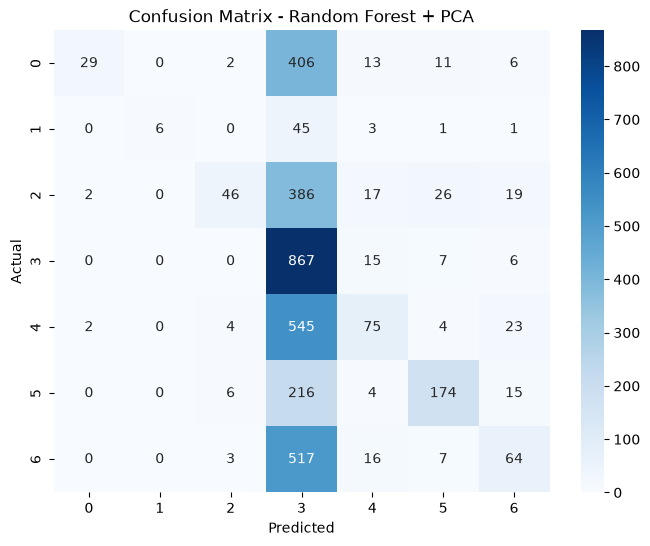

In [39]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


SVM + PCA

In [40]:
svm_pca = SVC(
    kernel='rbf',
    random_state=42
)

svm_pca.fit(X_pca_train_scaled, labelsTrain)

print("SVM + PCA trained successfully")


SVM + PCA trained successfully


Evaluate SVM + PCA in the validation test

In [41]:
y_pred_svm_pca = svm_pca.predict(X_pca_valid_scaled)

accuracy_svm_pca = accuracy_score(y_valid, y_pred_svm_pca)
baccuracy_svm_pca = balanced_accuracy_score(y_valid, y_pred_svm_pca)
macro_f1_svm_pca = f1_score(y_valid, y_pred_svm_pca, average='macro')

conf_matrix_svm_pca = confusion_matrix(y_valid, y_pred_svm_pca)

print(f"Accuracy: {accuracy_svm_pca:.2f}")
print(f"Balanced accuracy: {baccuracy_svm_pca:.2f}")
print(f"Macro F1: {macro_f1_svm_pca:.2f}")


Accuracy: 0.45
Balanced accuracy: 0.38
Macro F1: 0.40


Confusion Matrix - SVM + PCA

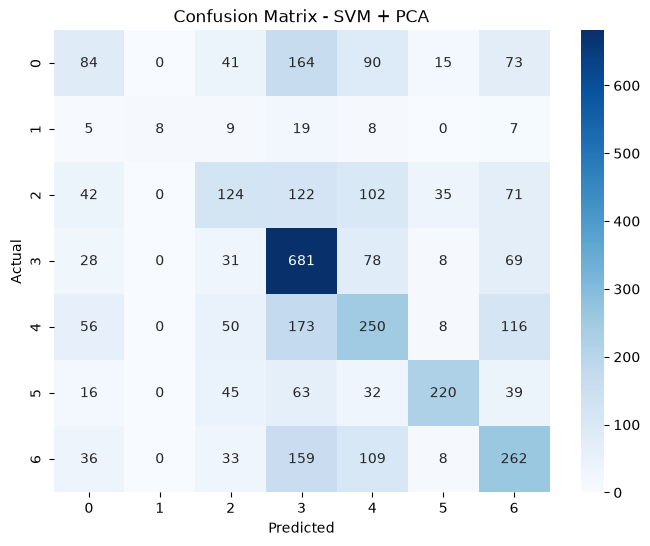

In [42]:
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm_pca, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - SVM + PCA")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Task 2

In [43]:
%pip install "opencv-python<5"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2.1 Indexing KDEF images

In [44]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}

# KDEF emotion label to FER2013 label map
KDEF_TO_FER = {
    "angry": 0, "disgust": 1, "afraid": 2, "happy": 3,
    "sad": 4, "surprise": 5, "neutral": 6,
}

emotionDict = {
    0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy',
    4: 'Sad', 5: 'Surprise', 6: 'Neutral',
}
class_names = [emotionDict[i] for i in range(7)]

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

records = []
for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    
    for emotion_code in EMOTIONS:
        
        if stem[4:].startswith(emotion_code):
            pose_code = stem[4 + len(emotion_code):]
            
            if pose_code in POSES:
                records.append({
                    "path": str(img_path),
                    "acquisition": stem[0],   # session A or B
                    "subject": stem[1:4],  
                    "emotion": EMOTIONS[emotion_code],
                    "pose": POSES[pose_code],
                })
                
            break

df = pd.DataFrame(records)
print("All KDEF images:", len(df))


All KDEF images: 4898


## 2.2 80/20 Split frontal images
Also is subject independent! 

In [45]:
with open("auxFiles/kdef_subject_split.pkl", "rb") as f:
    split_data = pickle.load(f)

train_subjects = set(split_data["train_subjects"])
test_subjects = set(split_data["test_subjects"])

# Selection filter for frontal images
frontal = df[df["pose"] == "straight"]

train_df = frontal[frontal["subject"].isin(train_subjects)].reset_index(drop=True)
test_df = frontal[frontal["subject"].isin(test_subjects)].reset_index(drop=True)

# Subject independence check: no identity may be in both sets
assert train_subjects.isdisjoint(test_subjects)
assert set(train_df["subject"]).isdisjoint(set(test_df["subject"]))

n_subj = len(train_subjects) + len(test_subjects)
print(f"Train subjects: {len(train_subjects)} ({len(train_subjects) / n_subj:.0%})")
print(f"Test subjects : {len(test_subjects)} ({len(test_subjects) / n_subj:.0%})")
print("Train images  :", len(train_df))
print("Test images   :", len(test_df))
print()
print(pd.crosstab(
    frontal["emotion"],
    frontal["subject"].isin(train_subjects).map({True: "train", False: "test"})))


Train subjects: 56 (80%)
Test subjects : 14 (20%)
Train images  : 784
Test images   : 196

subject   test  train
emotion              
afraid      28    112
angry       28    112
disgust     28    112
happy       28    112
neutral     28    112
sad         28    112
surprise    28    112


## 2.3 Preprocessing step 
The following steps are done below: 
- preprocess kdef image detects face
- Crops with a margin
- converts to grayscale and resizes to 48x48
- Rescaled to [0,255] such that they match FER2013 pixel range for training HOG pipeline

In [46]:
def load_split(dataFrame):
    images, labels, subjects = [], [], []
    
    for _, row in dataFrame.iterrows():
        try:
            img = preprocess_kdef_image(row["path"])
        except ValueError as e:
            print("Skipped:", e)
            continue
    
        images.append(img * 255.0)
        labels.append(KDEF_TO_FER[row["emotion"]])
        subjects.append(row["subject"])
    
    return np.array(images), np.array(labels), np.array(subjects)


X_train_img, y_train, groups_train = load_split(train_df)
X_test_img, y_test, groups_test = load_split(test_df)

print("Train:", X_train_img.shape, " Test:", X_test_img.shape)


Train: (784, 48, 48)  Test: (196, 48, 48)


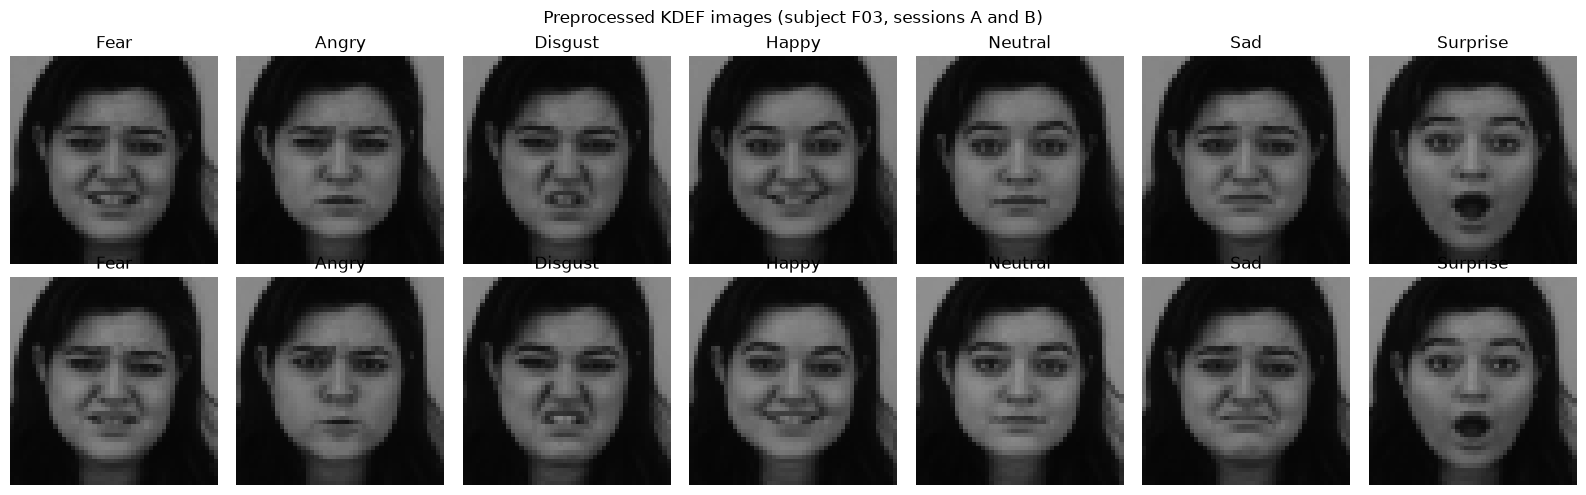

In [47]:
# Preprocessed samples
subj = groups_train[10]
idx = np.where(groups_train == subj)[0][:14]

fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train_img[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(emotionDict[y_train[i]])
    ax.axis("off")
    
fig.suptitle(f"Preprocessed KDEF images (subject {subj}, sessions A and B)")
plt.tight_layout()
plt.show()


## 2.4 Feature Extraction: HOG

In [48]:
def extractHOG(images):
    hog_features = []
    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
        hog_features.append(features)
    return np.array(hog_features)


hog_train = extractHOG(X_train_img)
hog_test = extractHOG(X_test_img)

print("HOG train shape:", hog_train.shape)
print("HOG test shape :", hog_test.shape)


HOG train shape: (784, 900)
HOG test shape : (196, 900)


## 2.5 Retraining of Classifier

Used the hyperparams from task1 notebook

In [49]:
models = {
    "SVM + HOG": SVC(
        kernel='rbf',
        random_state=42
    ),
    
    "Logistic Regression + HOG": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    
    "Random Forest + HOG": RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1,
        criterion="entropy"
    ),
}

for name, model in models.items():
    model.fit(hog_train, y_train)
    print(f"{name} trained")


SVM + HOG trained
Logistic Regression + HOG trained
Random Forest + HOG trained


## 2.6 Evaluation of retrained model

=== SVM + HOG ===
Accuracy: 0.58
Balanced accuracy: 0.58
Macro F1: 0.58
              precision    recall  f1-score   support

       Angry       0.55      0.43      0.48        28
     Disgust       0.74      0.61      0.67        28
        Fear       0.28      0.39      0.33        28
       Happy       0.92      0.79      0.85        28
         Sad       0.59      0.46      0.52        28
    Surprise       0.51      0.75      0.61        28
     Neutral       0.68      0.61      0.64        28

    accuracy                           0.58       196
   macro avg       0.61      0.58      0.58       196
weighted avg       0.61      0.58      0.58       196



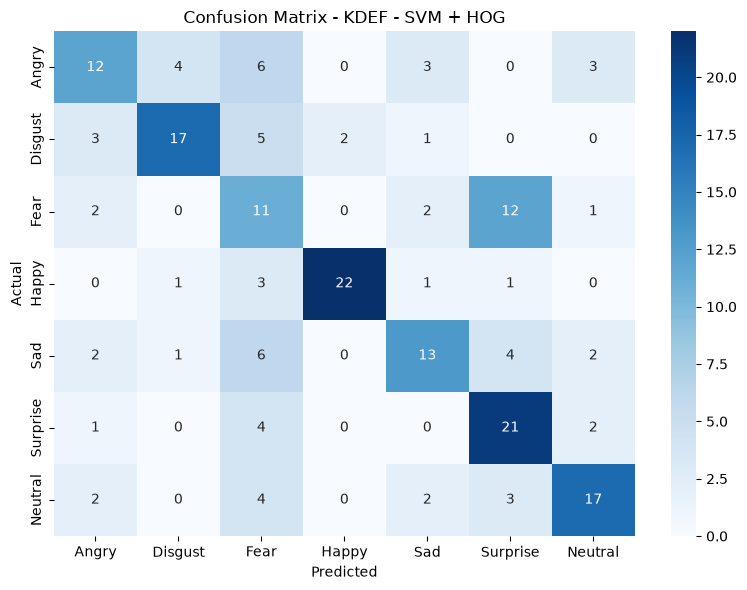

=== Logistic Regression + HOG ===
Accuracy: 0.56
Balanced accuracy: 0.56
Macro F1: 0.56
              precision    recall  f1-score   support

       Angry       0.58      0.39      0.47        28
     Disgust       0.79      0.54      0.64        28
        Fear       0.34      0.54      0.42        28
       Happy       0.91      0.75      0.82        28
         Sad       0.42      0.39      0.41        28
    Surprise       0.50      0.64      0.56        28
     Neutral       0.62      0.64      0.63        28

    accuracy                           0.56       196
   macro avg       0.60      0.56      0.56       196
weighted avg       0.60      0.56      0.56       196



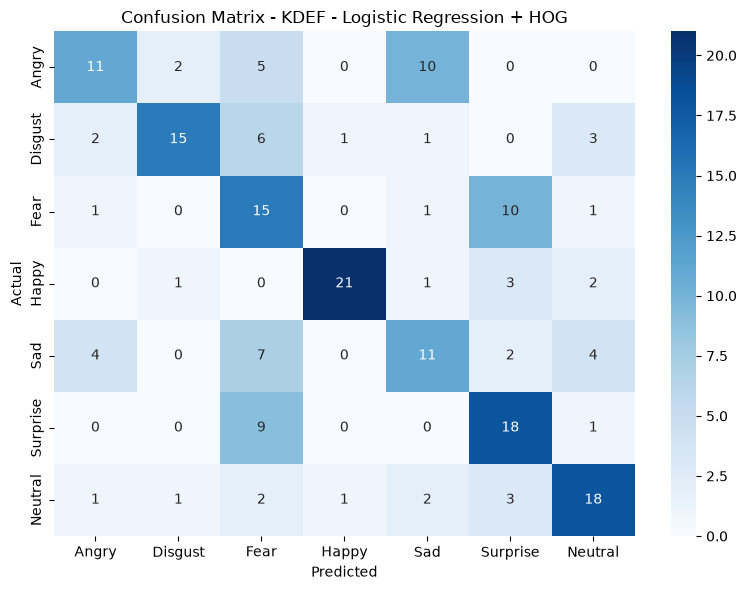

=== Random Forest + HOG ===
Accuracy: 0.63
Balanced accuracy: 0.63
Macro F1: 0.62
              precision    recall  f1-score   support

       Angry       0.85      0.61      0.71        28
     Disgust       0.76      0.68      0.72        28
        Fear       0.44      0.25      0.32        28
       Happy       0.70      0.93      0.80        28
         Sad       0.67      0.43      0.52        28
    Surprise       0.49      0.79      0.60        28
     Neutral       0.60      0.75      0.67        28

    accuracy                           0.63       196
   macro avg       0.64      0.63      0.62       196
weighted avg       0.64      0.63      0.62       196



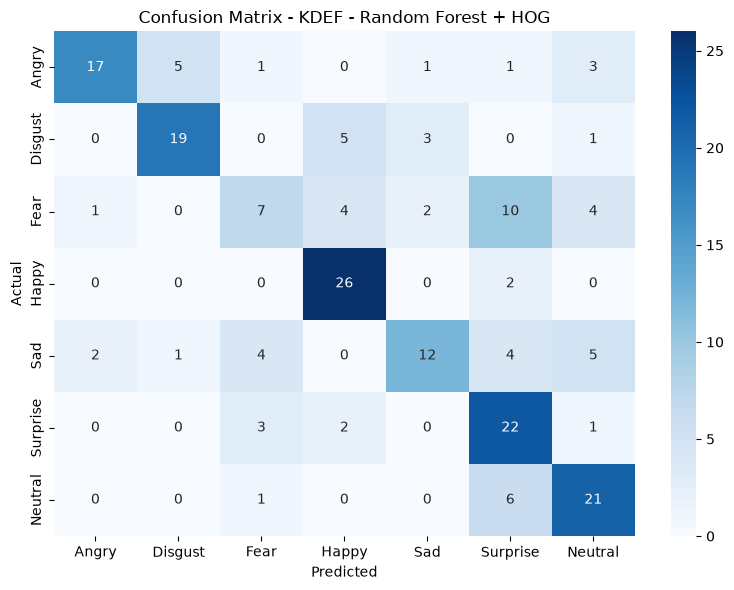

In [50]:
def evaluate(name, model, X, y):
    y_pred = model.predict(X)
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y, y_pred),
        "Macro F1": f1_score(y, y_pred, average='macro'),
    }

    print(f"=== {name} ===")
    print(f"Accuracy: {result['Accuracy']:.2f}")
    print(f"Balanced accuracy: {result['Balanced accuracy']:.2f}")
    print(f"Macro F1: {result['Macro F1']:.2f}")
    print(classification_report(y, y_pred, labels=range(7), target_names=class_names, zero_division=0))

    conf_matrix = confusion_matrix(y, y_pred, labels=range(7))
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - KDEF - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"figures/KDEF {name} Confusion Matrix.png")
    plt.show()
    return result


results = [evaluate(name, model, hog_test, y_test) for name, model in models.items()]


## 2.7 Cross Validation 


In [51]:
cv = GroupKFold(n_splits=5)
scoring = {"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy", "Macro F1": "f1_macro"}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, hog_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    
    for metric in scoring:
        s = scores[f"test_{metric}"]
        row[f"CV {metric}"] = f"{s.mean():.2f} +/- {s.std():.2f}"
    cv_rows.append(row)

pd.DataFrame(cv_rows).set_index("Model")


,CV Accuracy,CV Balanced accuracy,CV Macro F1
Model,,,
SVM + HOG,0.65 +/- 0.05,0.65 +/- 0.05,0.64 +/- 0.05
Logistic Regression + HOG,0.63 +/- 0.03,0.63 +/- 0.03,0.62 +/- 0.03
Random Forest + HOG,0.64 +/- 0.03,0.64 +/- 0.03,0.62 +/- 0.03


## 2.8 FER2013 Reference

To evaluate per emotion results the same 3 classifiers are trained on the FER2013 training set and evaluated on the validation set. 

In [52]:
fer_train = pd.read_csv("./data/fer2013_train.csv")
fer_valid = pd.read_csv("./data/fer2013_validation.csv")

def fer_images(dataFrame):
    return np.array([np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in dataFrame['pixels']])

hog_fer_train = extractHOG(fer_images(fer_train))
hog_fer_valid = extractHOG(fer_images(fer_valid))
y_fer_train = fer_train['emotion'].values
y_fer_valid = fer_valid['emotion'].values

fer_pred = {}
for name, model in models.items():
    fer_model = clone(model).fit(hog_fer_train, y_fer_train)
    fer_pred[name] = fer_model.predict(hog_fer_valid)
    print(f"{name} trained on FER2013")


SVM + HOG trained on FER2013
Logistic Regression + HOG trained on FER2013
Random Forest + HOG trained on FER2013


## 2.9 Ranking Model Change

In [53]:
kdef_pred = {name: model.predict(hog_test) for name, model in models.items()}

rank_rows = []
for name in models:
    rank_rows.append({
        "Model": name,
        "FER2013 accuracy": accuracy_score(y_fer_valid, fer_pred[name]),
        "FER2013 macro F1": f1_score(y_fer_valid, fer_pred[name], average='macro'),
        "KDEF accuracy": accuracy_score(y_test, kdef_pred[name]),
        "KDEF macro F1": f1_score(y_test, kdef_pred[name], average='macro'),
    })

ranking = pd.DataFrame(rank_rows).set_index("Model")
ranking["FER2013 rank"] = ranking["FER2013 macro F1"].rank(ascending=False, method="min").astype(int)
ranking["KDEF rank"] = ranking["KDEF macro F1"].rank(ascending=False, method="min").astype(int)
ranking.round(2)


,FER2013 accuracy,FER2013 macro F1,KDEF accuracy,KDEF macro F1,FER2013 rank,KDEF rank
Model,,,,,,
SVM + HOG,0.54,0.50,0.58,0.58,1,2
Logistic Regression + HOG,0.43,0.40,0.56,0.56,2,3
Random Forest + HOG,0.45,0.39,0.63,0.62,3,1


## 2.10 Emotions Transfer Analysis
We compare the models with the F1 score and created a barplot

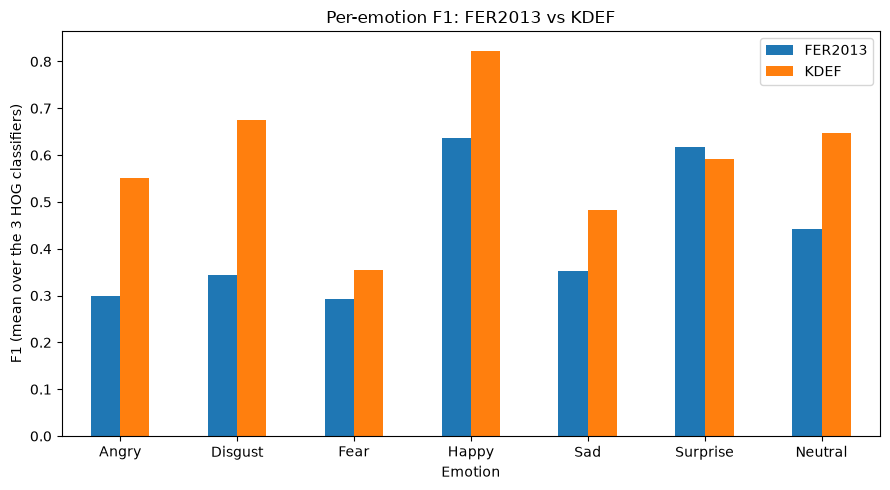

,FER2013,KDEF,Difference (KDEF - FER2013)
Emotion,,,
Angry,0.30,0.55,0.25
Disgust,0.34,0.67,0.33
Fear,0.29,0.35,0.06
Happy,0.64,0.82,0.19
Sad,0.35,0.48,0.13
Surprise,0.62,0.59,-0.03
Neutral,0.44,0.65,0.21


In [54]:
per_class = []
for name in models:
    f1_fer = f1_score(y_fer_valid, fer_pred[name], labels=range(7), average=None)
    f1_kdef = f1_score(y_test, kdef_pred[name], labels=range(7), average=None)
    for c in range(7):
        per_class.append({"Emotion": class_names[c], "Model": name,
                          "FER2013": f1_fer[c], "KDEF": f1_kdef[c]})

per_class = pd.DataFrame(per_class)
emotion_f1 = per_class.groupby("Emotion")[["FER2013", "KDEF"]].mean().reindex(class_names)
emotion_f1["Difference (KDEF - FER2013)"] = emotion_f1["KDEF"] - emotion_f1["FER2013"]

ax = emotion_f1[["FER2013", "KDEF"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("F1 (mean over the 3 HOG classifiers)")
ax.set_title("Per-emotion F1: FER2013 vs KDEF")
plt.tight_layout()
plt.savefig("figures/KDEF vs FER2013 per-emotion F1.png")
plt.show()

emotion_f1.round(2)


# Task 3

## 3.1 Data loading and preprocessing


In [55]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

KDEF_TO_FER = {
    "angry": 0, "disgust": 1, "afraid": 2, "happy": 3,
    "sad": 4, "surprise": 5, "neutral": 6,
}

emotionDict = {
    0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy',
    4: 'Sad', 5: 'Surprise', 6: 'Neutral',
}
class_names = [emotionDict[i] for i in range(7)]

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

records = []
for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    
    for emotion_code in EMOTIONS:
        # Frontal images only: pose code "S" (straight)
        if stem[4:] == emotion_code + "S":
            records.append({
                "path": str(img_path),
                "subject": stem[1:4],
                "emotion": EMOTIONS[emotion_code],
            })
            
            break

kdef_df = pd.DataFrame(records)
print("Frontal KDEF images:", len(kdef_df), "from", kdef_df["subject"].nunique(), "subjects")


Frontal KDEF images: 980 from 70 subjects


In [56]:
X_kdef_img, y_kdef, groups_kdef = [], [], []

for _, row in kdef_df.iterrows():
    try:
        img = preprocess_kdef_image(row["path"])
    except ValueError as e:
        print("Skipped:", e)
        continue

    X_kdef_img.append(img * 255.0)
    y_kdef.append(KDEF_TO_FER[row["emotion"]])
    groups_kdef.append(row["subject"])

X_kdef_img = np.array(X_kdef_img)
y_kdef = np.array(y_kdef)
groups_kdef = np.array(groups_kdef)

print("KDEF:", X_kdef_img.shape)


KDEF: (980, 48, 48)


## 3.2 Load test set of FER2013

In [57]:
fer_test = pd.read_csv("./data/fer2013_test.csv")

X_fer_img = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in fer_test['pixels']])

y_fer = fer_test['emotion'].values

print("FER2013 test:", X_fer_img.shape)
print(pd.Series(y_fer).map(emotionDict).value_counts())


FER2013 test: (3589, 48, 48)
Happy       879
Neutral     626
Sad         594
Fear        528
Angry       491
Surprise    416
Disgust      55
Name: count, dtype: int64


## 3.3 Domain Shift analysis: Dataset comparison

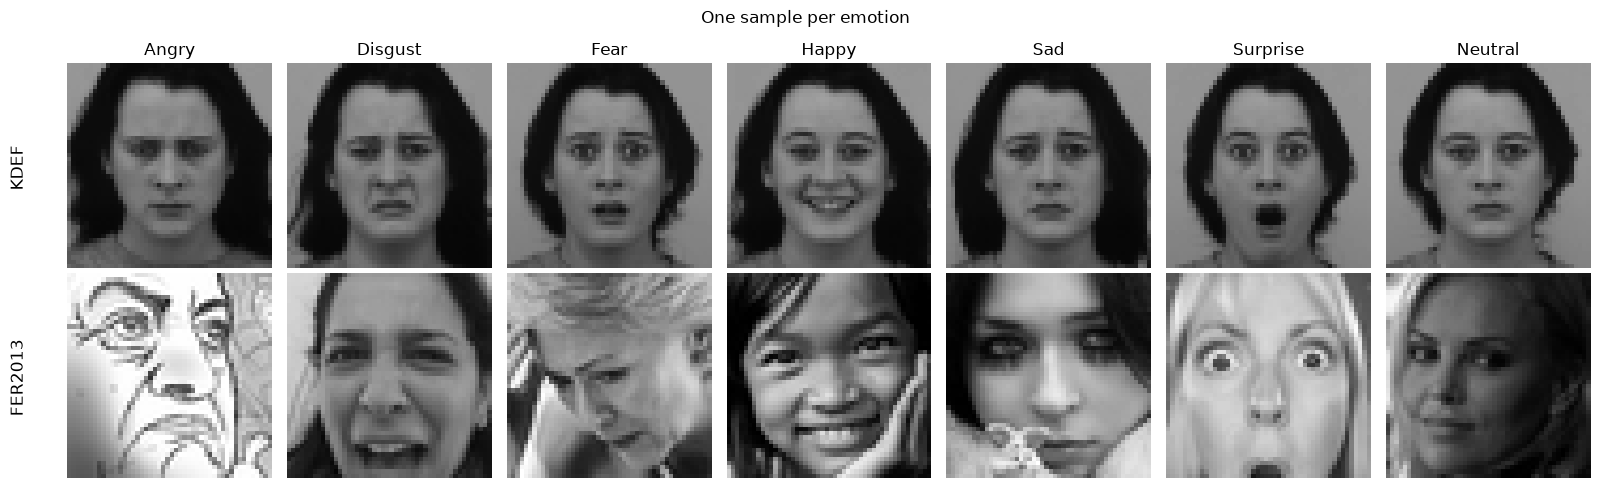

In [58]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5))

INDEX = 13

for c in range(7):
    k = np.where(y_kdef == c)[0][INDEX]
    f = np.where(y_fer == c)[0][INDEX]
    
    axes[0, c].imshow(X_kdef_img[k], cmap="gray", vmin=0, vmax=255)
    axes[1, c].imshow(X_fer_img[f], cmap="gray", vmin=0, vmax=255)
    axes[0, c].set_title(emotionDict[c])
    axes[0, c].axis("off")
    axes[1, c].axis("off")

axes[0, 0].text(-10, 24, "KDEF", rotation=90, va="center", ha="right", fontsize=12)
axes[1, 0].text(-10, 24, "FER2013", rotation=90, va="center", ha="right", fontsize=12)

plt.suptitle("One sample per emotion")
plt.tight_layout()
plt.show()


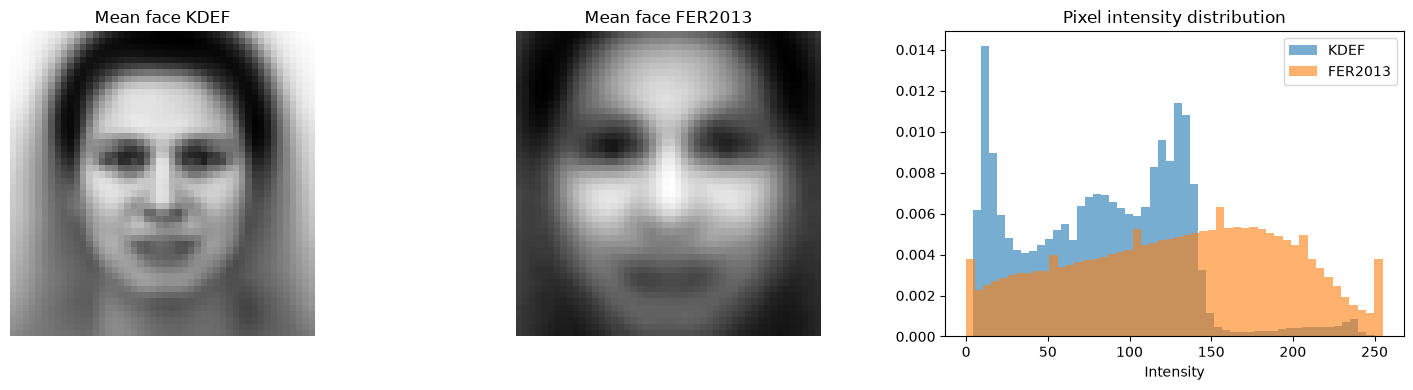

KDEF    mean 83.3  std 49.4
FER2013 mean 129.1  std 65.4


In [59]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(X_kdef_img.mean(axis=0), cmap="gray")
axes[0].set_title("Mean face KDEF")
axes[0].axis("off")

axes[1].imshow(X_fer_img.mean(axis=0), cmap="gray")
axes[1].set_title("Mean face FER2013")
axes[1].axis("off")

axes[2].hist(X_kdef_img.ravel(), bins=50, density=True, alpha=0.6, label="KDEF")
axes[2].hist(X_fer_img.ravel(), bins=50, density=True, alpha=0.6, label="FER2013")
axes[2].set_title("Pixel intensity distribution")
axes[2].set_xlabel("Intensity")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"KDEF    mean {X_kdef_img.mean():.1f}  std {X_kdef_img.std():.1f}")
print(f"FER2013 mean {X_fer_img.mean():.1f}  std {X_fer_img.std():.1f}")


## 3.4 Feature extraction

In [60]:
def extractHOG(images):
    hog_features = []
    
    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
    
        hog_features.append(features)
    return np.array(hog_features)


landmDet = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")


def extractLandmarksFER(images):
    face_rects = dlib.rectangle(left=1, top=1, right=47, bottom=47)
    x1 = face_rects.left()
    y1 = face_rects.top()
    x2 = face_rects.right()
    y2 = face_rects.bottom()

    landm = []
    for img in images:
        # Adaptation: dlib needs uint8 images
        la = landmDet(img.astype(np.uint8), face_rects)

        la2 = np.asarray(np.matrix([
            [
                (p.x - 0.5 * (x2 - x1)) / (x2 - x1), (p.y - 0.5 * (y2 - y1)) / (y2 - y1)
            ] for p in la.parts()])).astype(np.float32)
        la2 -= np.mean(la2, axis=0, keepdims=True)
        la2 /= np.max(np.abs(la2), axis=0, keepdims=True)

        landm.append(la2.flatten())
    return np.stack(landm)


# PCA is fitted on KDEF only: FER2013 must stay unseen
pca = PCA(n_components=0.95, random_state=42)
pca.fit(X_kdef_img.reshape(len(X_kdef_img), -1))

features = {
    "HOG": (extractHOG(X_kdef_img), extractHOG(X_fer_img)),
    "Landmarks": (extractLandmarksFER(X_kdef_img), extractLandmarksFER(X_fer_img)),
    "PCA": (pca.transform(X_kdef_img.reshape(len(X_kdef_img), -1)),
            pca.transform(X_fer_img.reshape(len(X_fer_img), -1))),
}

for name, (Xk, Xf) in features.items():
    print(f"{name:10s} KDEF {Xk.shape}  FER2013 {Xf.shape}")


HOG        KDEF (980, 900)  FER2013 (3589, 900)
Landmarks  KDEF (980, 136)  FER2013 (3589, 136)
PCA        KDEF (980, 72)  FER2013 (3589, 72)


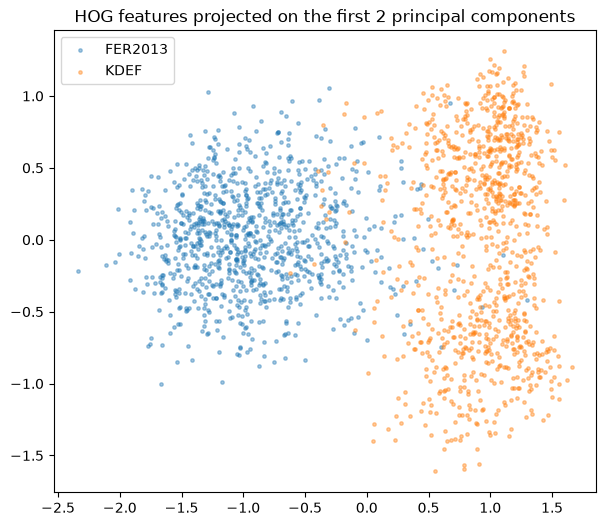

In [61]:
# 2D view of the HOG feature space: if both datasets overlapped, there would be no domain shift
rng = np.random.default_rng(42)
fer_sample = rng.choice(len(X_fer_img), size=len(X_kdef_img), replace=False)

hog_k, hog_f = features["HOG"]
proj = PCA(n_components=2, random_state=42).fit(np.vstack([hog_k, hog_f[fer_sample]]))

pk = proj.transform(hog_k)
pf = proj.transform(hog_f[fer_sample])

plt.figure(figsize=(7, 6))
plt.scatter(pf[:, 0], pf[:, 1], s=6, alpha=0.4, label="FER2013")
plt.scatter(pk[:, 0], pk[:, 1], s=6, alpha=0.4, label="KDEF")
plt.title("HOG features projected on the first 2 principal components")
plt.legend()
plt.show()


## 3.5 Retraining of best model Task 2

In [62]:
def make_model(classifier, feature):
    # Same configurations as Tasks 1 and 2
    if classifier == "Random Forest":
        return RandomForestClassifier(
            n_estimators=300,
            max_depth=11,
            max_features='sqrt',
            random_state=42,
            n_jobs=-1,
            criterion="entropy"
        )
    if classifier == "SVM":
        svm = SVC(kernel='rbf', random_state=42)
        return make_pipeline(StandardScaler(), svm) if feature == "PCA" else svm
    if classifier == "Logistic Regression":
        lr = LogisticRegression(max_iter=1000, random_state=42)
        return lr if feature == "Landmarks" else make_pipeline(StandardScaler(), lr)


def scores(y, y_pred):
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y, y_pred),
        "Macro F1": f1_score(y, y_pred, average='macro'),
    }


def show_confusion(y, y_pred, title):
    conf_matrix = confusion_matrix(y, y_pred, labels=range(7), normalize="true")
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"figures/{title}.png")
    plt.show()


=== Random Forest + HOG: trained on KDEF, tested on FER2013 ===
Accuracy: 0.21
Balanced accuracy: 0.20
Macro F1: 0.16
              precision    recall  f1-score   support

       Angry       0.19      0.05      0.07       491
     Disgust       0.04      0.09      0.06        55
        Fear       0.14      0.16      0.15       528
       Happy       0.41      0.32      0.36       879
         Sad       0.17      0.20      0.18       594
    Surprise       0.18      0.57      0.27       416
     Neutral       0.27      0.01      0.02       626

    accuracy                           0.21      3589
   macro avg       0.20      0.20      0.16      3589
weighted avg       0.24      0.21      0.19      3589

Predicted class distribution:
Angry        124
Disgust      114
Fear         623
Happy        681
Sad          702
Surprise    1315
Neutral       30


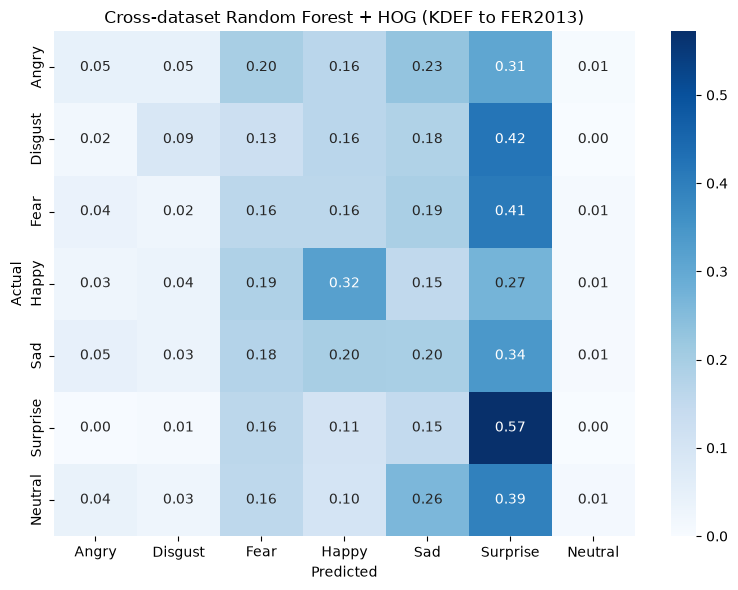

=== SVM + HOG: trained on KDEF, tested on FER2013 ===
Accuracy: 0.21
Balanced accuracy: 0.21
Macro F1: 0.18
              precision    recall  f1-score   support

       Angry       0.16      0.40      0.23       491
     Disgust       0.02      0.18      0.04        55
        Fear       0.15      0.07      0.09       528
       Happy       0.66      0.20      0.31       879
         Sad       0.19      0.30      0.24       594
    Surprise       0.32      0.32      0.32       416
     Neutral       0.20      0.00      0.00       626

    accuracy                           0.21      3589
   macro avg       0.24      0.21      0.18      3589
weighted avg       0.31      0.21      0.20      3589

Predicted class distribution:
Angry       1220
Disgust      472
Fear         254
Happy        267
Sad          946
Surprise     425
Neutral        5


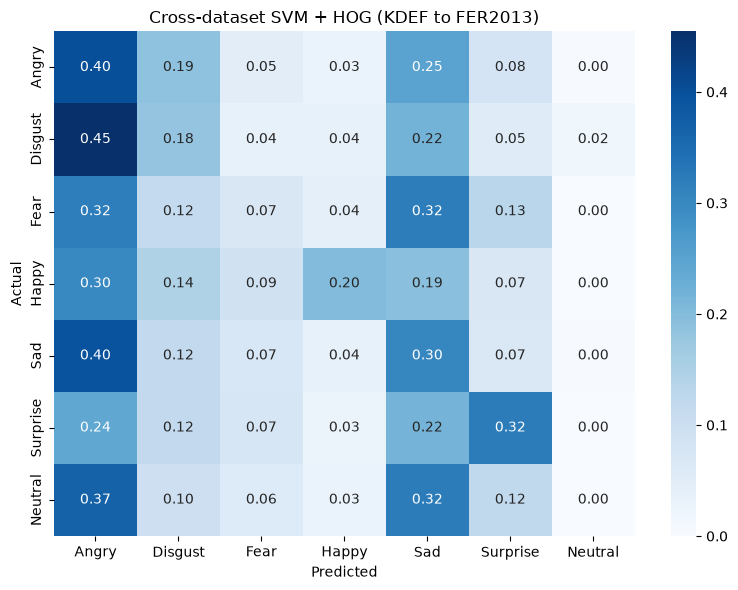

In [63]:
Xk, Xf = features["HOG"]

for classifier in ["Random Forest", "SVM"]:
    model = make_model(classifier, "HOG")
    model.fit(Xk, y_kdef)
    y_pred = model.predict(Xf)

    s = scores(y_fer, y_pred)
    print(f"=== {classifier} + HOG: trained on KDEF, tested on FER2013 ===")
    print(f"Accuracy: {s['Accuracy']:.2f}")
    print(f"Balanced accuracy: {s['Balanced accuracy']:.2f}")
    print(f"Macro F1: {s['Macro F1']:.2f}")
    print(classification_report(y_fer, y_pred, labels=range(7), target_names=class_names, zero_division=0))
    print("Predicted class distribution:")
    print(pd.Series(y_pred).map(emotionDict).value_counts().reindex(class_names, fill_value=0).to_string())
    show_confusion(y_fer, y_pred, f"Cross-dataset {classifier} + HOG (KDEF to FER2013)")


## 3.6 Feature Transfer

In [64]:
cv = GroupKFold(n_splits=5)
rows = []

for feature, (Xk, Xf) in features.items():
    for classifier in ["Random Forest", "SVM", "Logistic Regression"]:
        in_pred = cross_val_predict(
            make_model(classifier, feature), Xk, y_kdef, groups=groups_kdef, cv=cv)
        
        f1_in = f1_score(y_kdef, in_pred, average='macro')
        model = make_model(classifier, feature).fit(Xk, y_kdef)
        cross = scores(y_fer, model.predict(Xf))

        rows.append({
            "Features": feature,
            "Classifier": classifier,
            "In-domain macro F1 (KDEF CV)": f1_in,
            "Cross accuracy (FER2013)": cross["Accuracy"],
            "Cross balanced acc. (FER2013)": cross["Balanced accuracy"],
            "Cross macro F1 (FER2013)": cross["Macro F1"],
            "Retained": cross["Macro F1"] / f1_in,
        })

transfer = pd.DataFrame(rows).set_index(["Features", "Classifier"])
transfer.round(2)


In-domain macro F1 (KDEF CV)  \
Features  Classifier                                          
HOG       Random Forest                                0.61   
          SVM                                          0.64   
          Logistic Regression                          0.61   
Landmarks Random Forest                                0.51   
          SVM                                          0.41   
          Logistic Regression                          0.49   
PCA       Random Forest                                0.54   
          SVM                                          0.68   
          Logistic Regression                          0.58   

                               Cross accuracy (FER2013)  \
Features  Classifier                                      
HOG       Random Forest                            0.21   
          SVM                                      0.21   
          Logistic Regression                      0.25   
Landmarks Random Forest                            0.29   
          SVM                                      0.26   
          Logistic Regression                      0.31   
PCA       Random Forest                            0.16   
          SVM                                      0.07   
          Logistic Regression                      0.17   

                               Cross balanced acc. (FER2013)  \
Features  Classifier                                           
HOG       Random Forest                                 0.20   
          SVM                                           0.21   
          Logistic Regression                           0.23   
Landmarks Random Forest                                 0.25   
          SVM                                           0.24   
          Logistic Regression                           0.29   
PCA       Random Forest                                 0.17   
          SVM                                           0.14   
          Logistic Regression                           0.16   

                               Cross macro F1 (FER2013)  Retained  
Features  Classifier                                               
HOG       Random Forest                            0.16      0.26  
          SVM                                      0.18      0.27  
          Logistic Regression                      0.20      0.32  
Landmarks Random Forest                            0.25      0.49  
          SVM                                      0.21      0.52  
          Logistic Regression                      0.26      0.52  
PCA       Random Forest                            0.13      0.25  
          SVM                                      0.07      0.10  
          Logistic Regression                      0.14      0.25

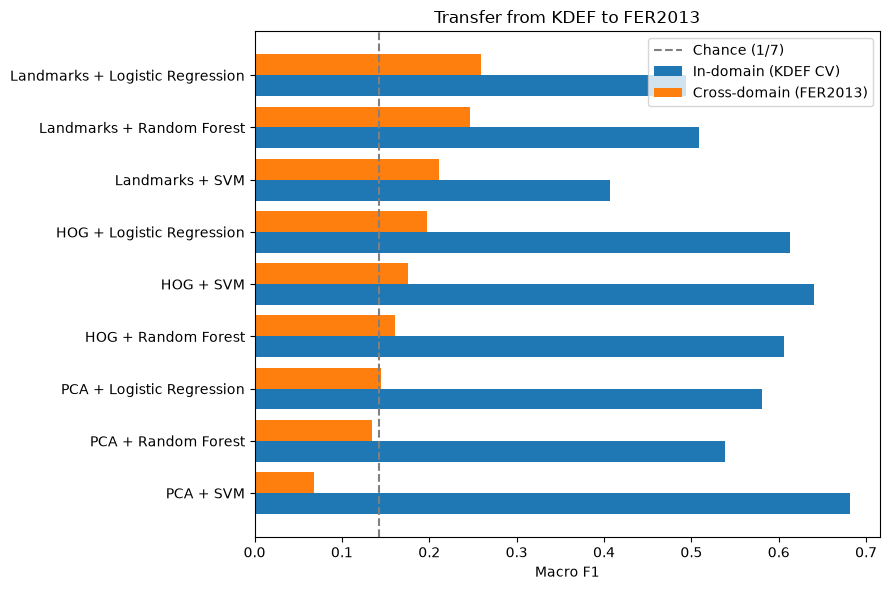

In [65]:
plot_df = transfer.reset_index()
plot_df["Model"] = plot_df["Features"] + " + " + plot_df["Classifier"]
plot_df = plot_df.sort_values("Cross macro F1 (FER2013)")

y = np.arange(len(plot_df))
plt.figure(figsize=(9, 6))
plt.barh(y - 0.2, plot_df["In-domain macro F1 (KDEF CV)"], height=0.4, label="In-domain (KDEF CV)")
plt.barh(y + 0.2, plot_df["Cross macro F1 (FER2013)"], height=0.4, label="Cross-domain (FER2013)")

plt.axvline(1 / 7, color="grey", linestyle="--", label="Chance (1/7)")
plt.yticks(y, plot_df["Model"])
plt.xlabel("Macro F1")

plt.title("Transfer from KDEF to FER2013")
plt.legend()
plt.tight_layout()
plt.savefig("figures/Cross-dataset transfer per feature.png")
plt.show()


In [66]:
# Average over the three classifiers, per feature type
transfer.groupby("Features")[["In-domain macro F1 (KDEF CV)", "Cross macro F1 (FER2013)", "Retained"]].mean().round(2)


,In-domain macro F1 (KDEF CV),Cross macro F1 (FER2013),Retained
Features,,,
HOG,0.62,0.18,0.29
Landmarks,0.47,0.24,0.51
PCA,0.60,0.12,0.20


# Task 5

All Task 5 run switches are `False`. Outputs are from completed runs. After a kernel restart, enable required preparation and training steps before executing this section.

# Task 5 - Improving FER2013 emotion recognition

The aim is to improve FER2013 predictions using class balancing, augmentation, tuning and feature selection. Image quality is also inspected.

Training is used to fit models. PublicTest is used to compare settings. PrivateTest is reserved for final evaluation. Results below use PublicTest unless stated otherwise.

## 1. Imports

The next cell loads the tools for image processing, model training and evaluation.

## 2. Load Training and PublicTest

The following cells load the images and emotion labels. They check the labels and count images in each class.

**Result:** Training contains 28,709 images. PublicTest contains 3,589. Happy has 7,215 training images, while Disgust has 436. This imbalance motivates class weighting.

In [67]:
BASE = Path(".")

train_df = pd.read_csv(
    BASE / "data/fer2013_train.csv"
)

valid_df = pd.read_csv(
    BASE / "data/fer2013_validation.csv"
)

class_names = [
    "Angry", "Disgust", "Fear", "Happy",
    "Sad", "Surprise", "Neutral"
]

y_train = train_df["emotion"].to_numpy()
y_valid = valid_df["emotion"].to_numpy()

print("Training images:", len(train_df))
print("Validation images:", len(valid_df))


Training images: 28709
Validation images: 3589


In [68]:
classes = np.arange(7)
assert np.isin(y_train, classes).all()
assert np.isin(y_valid, classes).all()

# These names refer to the same training rows.
trai_df = train_df
labelsTrain = y_train


,Emotion,Training images
0,Angry,3995
1,Disgust,436
2,Fear,4097
3,Happy,7215
4,Sad,4830
5,Surprise,3171
6,Neutral,4965


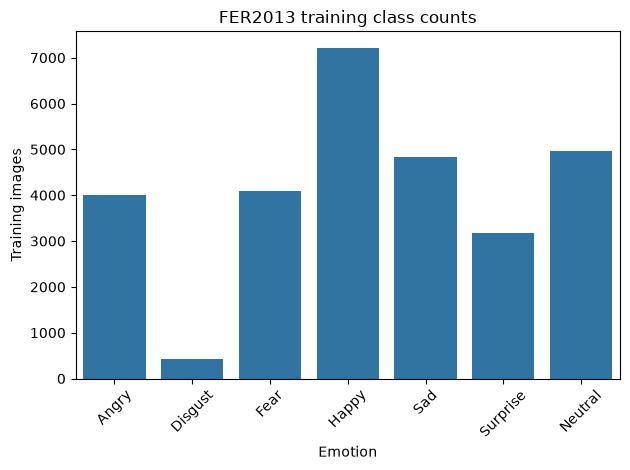

In [69]:
class_counts = (
    train_df["emotion"]
    .value_counts()
    .sort_index()
)

count_table = pd.DataFrame({
    "Emotion": class_names,
    "Training images": class_counts.reindex(
        range(7), fill_value=0
    ).to_numpy()
})

display(count_table)

sns.barplot(
    data=count_table,
    x="Emotion",
    y="Training images"
)

plt.xticks(rotation=45)
plt.title("FER2013 training class counts")
plt.tight_layout()
plt.show()


## 3. Inspect training image quality

The following cells measure average brightness and pixel variation. They display the 20 darkest training images and count completely black images. Low brightness alone is not a reason to remove an image.

In [70]:
RUN_IMAGE_INSPECTION = False

if RUN_IMAGE_INSPECTION:


    train_images = np.array([
        np.fromstring(pixels, sep=' ').reshape(48, 48)
        for pixels in trai_df['pixels']
    ])

    mean_brightness = train_images.mean(axis=(1, 2))
    std_brightness = train_images.std(axis=(1, 2))

    for threshold in [5, 10, 15, 20, 25, 30]:
        count = np.sum(mean_brightness <= threshold)
        print(f"Mean brightness <= {threshold}: {count} images")

    for threshold in [2, 3, 5, 8, 10]:
        count = np.sum(std_brightness <= threshold)
        print(f"Standard deviation <= {threshold}: {count} images")

    print("Number of training images:", len(train_images))
    print("Images with mean brightness <= 5:",
          np.sum(mean_brightness <= 5))
    print("Images with standard deviation <= 2:",
          np.sum(std_brightness <= 2))

    darkest_indices = np.argsort(mean_brightness)[:20]

    fig, axes = plt.subplots(4, 5, figsize=(12, 9))

    for ax, idx in zip(axes.flat, darkest_indices):
        ax.imshow(train_images[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"Label: {trai_df.iloc[idx]['emotion']}\n"
            f"Mean: {mean_brightness[idx]:.1f}, "
            f"Std: {std_brightness[idx]:.1f}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print('Image inspection skipped; previous outputs remain available.')


Image inspection skipped; previous outputs remain available.


In [71]:
if RUN_IMAGE_INSPECTION:

    black_mask = (train_images == 0).all(axis=(1, 2))

    print("Completely black images:", black_mask.sum())

    print("\nEmotion labels of black images:")
    print(trai_df.loc[black_mask, "emotion"].value_counts().sort_index())


**Result:** 11 training images are completely black. They contain no facial information. They were retained, so this inspection does not demonstrate a performance improvement.

## 4. Extract HOG features

The function converts each pixel string into a 48 x 48 image. It then measures local edges with HOG.

In [74]:
RUN_HOG_EXTRACTION = True

def extract_hog_from_dataframe(dataframe):
    """Return one HOG feature vector per image."""
    feature_rows = []

    for pixels in dataframe["pixels"]:
        image = np.fromstring(
            pixels,
            sep=" ",
            dtype=np.uint8
        ).reshape(48, 48)

        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        feature_rows.append(features)

    return np.asarray(feature_rows, dtype=np.float32)

if RUN_HOG_EXTRACTION:
    X_train_hog = extract_hog_from_dataframe(train_df)

    X_valid_hog = extract_hog_from_dataframe(valid_df)

    print("Training features:", X_train_hog.shape)

    print("Validation features:", X_valid_hog.shape)
else:
    print("HOG extraction skipped; reuse features already in this kernel.")


Training features: (28709, 900)
Validation features: (3589, 900)


In [75]:
assert X_train_hog.shape == (len(y_train), 900)
assert X_valid_hog.shape == (len(y_valid), 900)
assert np.isfinite(X_train_hog).all()
assert np.isfinite(X_valid_hog).all()

hog_feats = X_train_hog
hog_valid = X_valid_hog


## 5. Evaluation functions and class weights

The following cells calculate class weights and define common evaluation functions. Macro F1 gives equal importance to each emotion. Balanced accuracy is the average recall across emotions.

In [76]:
classes = np.arange(7)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

weight_table = pd.DataFrame({
    "Emotion": class_names,
    "Weight": weights
})

display(weight_table.round(3))


,Emotion,Weight
0,Angry,1.027
1,Disgust,9.407
2,Fear,1.001
3,Happy,0.568
4,Sad,0.849
5,Surprise,1.293
6,Neutral,0.826


In [77]:
classes = np.unique(y_train)

full_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

selected_weights = {}

# The exponent softens the full balanced weights.
for label, weight in zip(classes, full_weights):
    selected_weights[int(label)] = float(weight ** 0.75)

print("Class weights:", selected_weights)


Class weights: {0: 1.0198878809708158, 1: 5.3712473448255755, 2: 1.0007844436428528, 3: 0.6546554193397086, 4: 0.8845648359477872, 5: 1.2128101905683368, 6: 0.8664641118338571}


In [78]:
def create_forest(depth=11, minimum_leaf=1):
    """Create a forest with the selected class weights."""
    return RandomForestClassifier(
        n_estimators=300,
        max_depth=depth,
        min_samples_leaf=minimum_leaf,
        max_features="sqrt",
        criterion="entropy",
        class_weight=selected_weights,
        random_state=42,
        n_jobs=-1
    )

def evaluate_predictions(name, predictions):
    """Calculate validation scores for one experiment."""
    return {
        "Experiment": name,
        "Accuracy": accuracy_score(
            y_valid, predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, predictions
        ),
        "Macro F1": f1_score(
            y_valid,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )
    }


In [79]:
def record_result(name, model, predictions=None, columns=None):
    """Add a model and its scores to the comparison."""
    features = X_valid_hog if columns is None else X_valid_hog[:, columns]
    if predictions is None:
        predictions = model.predict(features)
    result = evaluate_predictions(name, predictions)
    validation_results[:] = [
        row for row in validation_results if row["Experiment"] != name
    ]
    validation_results.append(result)
    candidate_models[name] = (model, columns)
    return result

validation_results = []

candidate_models = {}


## 6. Random Forest baseline and class balancing

The following cells train two forests with the same settings: one uses no class weights and the other uses balanced weights. Their validation scores and confusion matrices show the effect of weighting.

In [84]:
RUN_BASELINE_TRAINING = True

if RUN_BASELINE_TRAINING:
    baseline_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features="sqrt",
        criterion="entropy",
        random_state=42,
        n_jobs=-1,
        class_weight=None
    )

    baseline_model.fit(X_train_hog, y_train)
    print("Baseline model trained.")
else:
    print('Baseline training skipped; reuse the trained model in this kernel.')

RUN_BALANCED_TRAINING = True

if RUN_BALANCED_TRAINING:
    balanced_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=11,
        max_features="sqrt",
        criterion="entropy",
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    balanced_model.fit(X_train_hog, y_train)
    print("Balanced model trained.")
else:
    print('Balanced training skipped; reuse the trained model in this kernel.')


Baseline model trained.
Balanced model trained.


In [85]:
baseline_predictions = baseline_model.predict(X_valid_hog)

balanced_predictions = balanced_model.predict(X_valid_hog)

predictions = {
    "Baseline": baseline_predictions,
    "Balanced weights": balanced_predictions
}

results = []

for name, predicted_labels in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_valid, predicted_labels
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, predicted_labels
        ),
        "Macro F1": f1_score(
            y_valid,
            predicted_labels,
            labels=range(7),
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))


,Model,Accuracy,Balanced accuracy,Macro F1
0,Baseline,0.453,0.376,0.388
1,Balanced weights,0.465,0.447,0.440


In [86]:
for name, predicted_labels in predictions.items():
    print("\n", name)

    print(classification_report(
        y_valid,
        predicted_labels,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))



 Baseline
              precision    recall  f1-score   support

       Angry       0.47      0.12      0.19       467
     Disgust       1.00      0.20      0.33        56
        Fear       0.55      0.18      0.27       496
       Happy       0.43      0.92      0.58       895
         Sad       0.43      0.25      0.31       653
    Surprise       0.77      0.53      0.63       415
     Neutral       0.38      0.44      0.40       607

    accuracy                           0.45      3589
   macro avg       0.57      0.38      0.39      3589
weighted avg       0.49      0.45      0.41      3589


 Balanced weights
              precision    recall  f1-score   support

       Angry       0.39      0.31      0.34       467
     Disgust       0.53      0.45      0.49        56
        Fear       0.42      0.24      0.30       496
       Happy       0.53      0.74      0.62       895
         Sad       0.37      0.29      0.32       653
    Surprise       0.53      0.73      0.61     

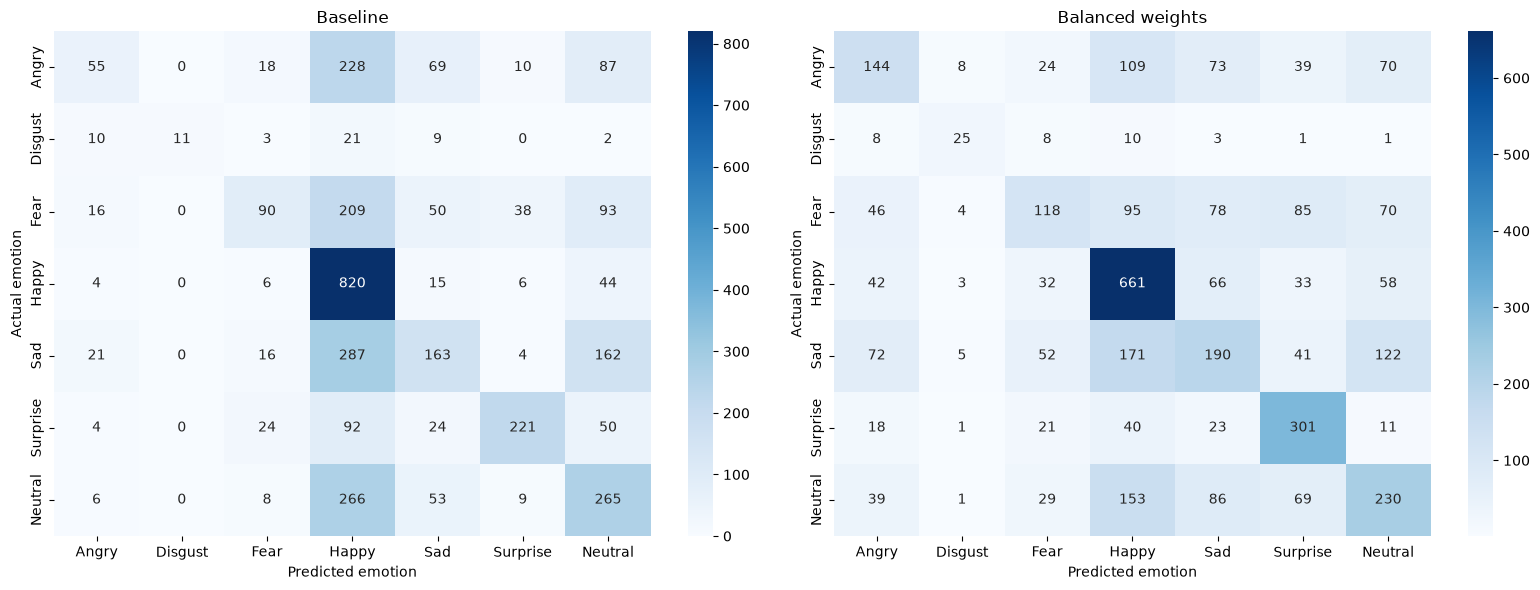

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, predicted_labels) in zip(
    axes, predictions.items()
):
    matrix = confusion_matrix(
        y_valid,
        predicted_labels,
        labels=range(7)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted emotion")
    ax.set_ylabel("Actual emotion")

plt.tight_layout()
plt.show()


In [88]:
record_result("RF baseline", baseline_model, baseline_predictions)
record_result("RF balanced weights", balanced_model, balanced_predictions)


{'Experiment': 'RF balanced weights',
 'Accuracy': 0.46503204235163,
 'Balanced accuracy': 0.44662987558623884,
 'Macro F1': 0.4402159897466632}

### Optional weight-strength search

The next cell compares weight exponents of 0.5, 0.75 and 1.25. It is skipped in the recorded run. The following forest uses the fixed exponent 0.75.


In [89]:
RUN_WEIGHT_SEARCH = False

if RUN_WEIGHT_SEARCH:

    classes = np.unique(y_train)

    full_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    extra_results = []

    for strength in [0.5, 0.75, 1.25]:
        custom_weights = {
            int(label): float(weight ** strength)
            for label, weight in zip(classes, full_weights)
        }

        model = clone(baseline_model)
        model.set_params(class_weight=custom_weights)

        model.fit(X_train_hog, y_train)
        predicted = model.predict(X_valid_hog)

        record_result(f"RF weight strength {strength}", model, predicted)

        extra_results.append({
            "Model": f"Weight strength {strength}",
            "Accuracy": accuracy_score(y_valid, predicted),
            "Balanced accuracy": balanced_accuracy_score(
                y_valid, predicted
            ),
            "Macro F1": f1_score(
                y_valid,
                predicted,
                labels=classes,
                average="macro",
                zero_division=0
            )
        })

        print(f"Finished strength {strength}")

    comparison_results = pd.concat(
        [results_df, pd.DataFrame(extra_results)],
        ignore_index=True
    )

    display(
        comparison_results
        .sort_values("Macro F1", ascending=False)
        .round(3)
    )

else:
    print("Weight search skipped. Selected strength: 0.75")


Weight search skipped. Selected strength: 0.75


In [90]:
RUN_REFERENCE_TRAINING = True

if RUN_REFERENCE_TRAINING:
    reference_model = create_forest(
        depth=11,
        minimum_leaf=1
    )

    reference_model.fit(X_train_hog, y_train)
else:
    print('Reference training skipped; reuse the trained model in this kernel.')

reference_predictions = reference_model.predict(
    X_valid_hog
)

reference_result = evaluate_predictions(
    "Reference: 0.75 weights, all features",
    reference_predictions
)

display(pd.DataFrame([reference_result]).round(3))


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"Reference: 0.75 weights, all features",0.472,0.43,0.443


In [91]:
record_result("RF 0.75 weights, depth 11", reference_model, reference_predictions)


{'Experiment': 'RF 0.75 weights, depth 11',
 'Accuracy': 0.4717191418222346,
 'Balanced accuracy': 0.42967676569231333,
 'Macro F1': 0.4425188114243878}

## 7. Data augmentation

The following cells flip, rotate, shift and slightly change the brightness of training images. They extract HOG features from the new images and train an unweighted forest. Validation images are unchanged.

In [92]:
def augment_image(image, rng):
    """Flip, rotate, shift and adjust image brightness."""
    modified = image.copy()

    if rng.random() < 0.5:
        modified = cv2.flip(modified, 1)

    angle = rng.uniform(-8, 8)
    shift_x = rng.uniform(-2, 2)
    shift_y = rng.uniform(-2, 2)

    height, width = modified.shape

    # Keep changes small to preserve the expression.
    matrix = cv2.getRotationMatrix2D(
        ((width - 1) / 2, (height - 1) / 2),
        angle,
        1.0
    )

    matrix[0, 2] += shift_x
    matrix[1, 2] += shift_y

    modified = cv2.warpAffine(
        modified,
        matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT_101
    )

    # Keep pixel values between 0 and 255.
    brightness = rng.uniform(0.9, 1.1)

    modified = np.clip(
        modified.astype(np.float32) * brightness,
        0, 255
    ).astype(np.uint8)

    return modified


In [93]:
y_train = np.asarray(y_train)

assert np.array_equal(
    train_df["emotion"].to_numpy(),
    y_train
)

assert len(X_train_hog) == len(y_train)

counts = (
    train_df["emotion"]
    .value_counts()
    .sort_index()
)

target_size = int(np.median(counts.to_numpy()))

plan = []

for label, original_count in counts.items():

    # Keep every original image. Limit each class to four times its size.
    final_count = max(
        original_count,
        min(target_size, 4 * original_count)
    )

    plan.append({
        "Label": int(label),
        "Emotion": class_names[int(label)],
        "Original": int(original_count),
        "Add": int(final_count - original_count),
        "Final": int(final_count)
    })

augmentation_plan = pd.DataFrame(plan)

display(augmentation_plan)


,Label,Emotion,Original,Add,Final
0,0,Angry,3995,102,4097
1,1,Disgust,436,1308,1744
2,2,Fear,4097,0,4097
3,3,Happy,7215,0,7215
4,4,Sad,4830,0,4830
5,5,Surprise,3171,926,4097
6,6,Neutral,4965,0,4965


In [97]:
RUN_AUGMENTATION_GENERATION = True

if RUN_AUGMENTATION_GENERATION:
    rng = np.random.default_rng(42)

    extra_images = []
    extra_labels = []
    source_indices = []

    for _, item in augmentation_plan.iterrows():
        label = int(item["Label"])
        number_to_add = int(item["Add"])

        available_indices = np.flatnonzero(y_train == label)

        for _ in range(number_to_add):
            source_idx = int(rng.choice(available_indices))

            image = np.fromstring(
                train_df.iloc[source_idx]["pixels"],
                sep=" ",
                dtype=np.uint8
            ).reshape(48, 48)

            modified = augment_image(image, rng)

            extra_images.append(modified)
            extra_labels.append(label)
            source_indices.append(source_idx)

    extra_images = np.asarray(
        extra_images, dtype=np.uint8
    ).reshape(-1, 48, 48)

    extra_labels = np.asarray(
        extra_labels, dtype=y_train.dtype
    )

    print("Extra training images:", len(extra_images))
else:
    print('Image generation skipped; reuse augmented images in this kernel.')


Extra training images: 2336


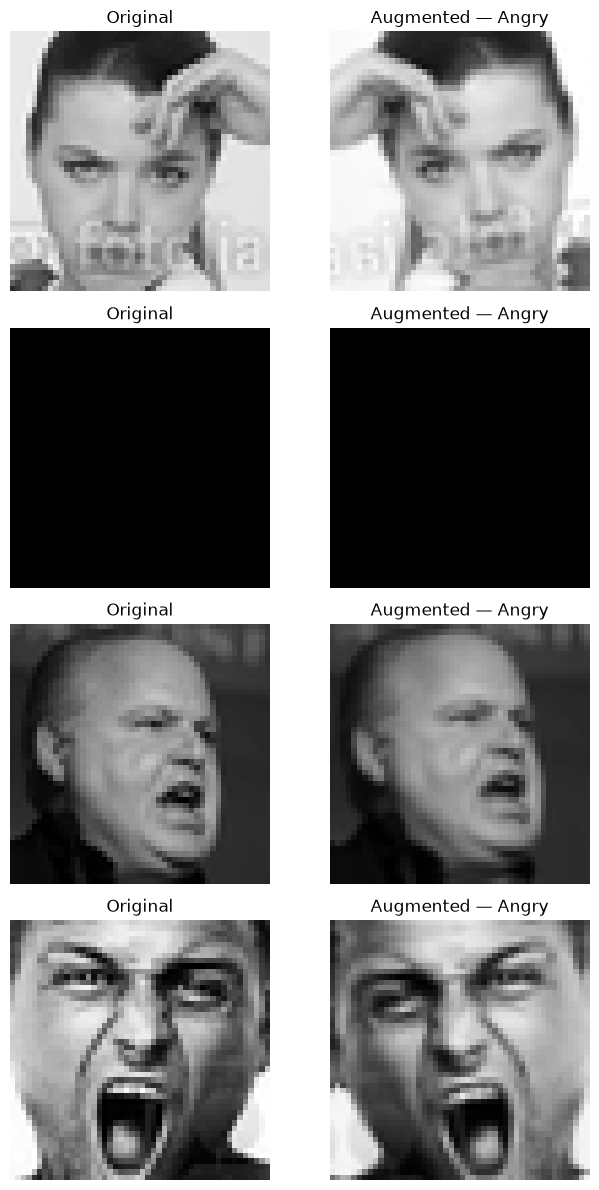

In [98]:
number_to_show = min(4, len(extra_images))

if number_to_show > 0:
    fig, axes = plt.subplots(
        number_to_show,
        2,
        figsize=(7, 3 * number_to_show),
        squeeze=False
    )

    for i in range(number_to_show):
        original = np.fromstring(
            train_df.iloc[source_indices[i]]["pixels"],
            sep=" ",
            dtype=np.uint8
        ).reshape(48, 48)

        axes[i, 0].imshow(
            original, cmap="gray", vmin=0, vmax=255
        )
        axes[i, 0].set_title("Original")

        axes[i, 1].imshow(
            extra_images[i], cmap="gray", vmin=0, vmax=255
        )
        axes[i, 1].set_title(
            f"Augmented — {class_names[int(extra_labels[i])]}"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


In [99]:
RUN_AUGMENTED_HOG = True

if RUN_AUGMENTED_HOG:
    extra_hog = []

    for image in extra_images:
        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        extra_hog.append(features)

    extra_hog = np.asarray(
        extra_hog, dtype=np.float32
    ).reshape(-1, X_train_hog.shape[1])
else:
    print('Augmented HOG skipped; reuse augmented features in this kernel.')

# Add training features without changing validation data.
X_train_augmented = np.concatenate(
    [X_train_hog, extra_hog],
    axis=0
)

y_train_augmented = np.concatenate(
    [y_train, extra_labels]
)

print("Original training shape:", X_train_hog.shape)
print("Augmented training shape:", X_train_augmented.shape)


Original training shape: (28709, 900)
Augmented training shape: (31045, 900)


In [100]:
RUN_AUGMENTATION_TRAINING = True

if RUN_AUGMENTATION_TRAINING:
    augmented_model = clone(baseline_model)

    augmented_model.set_params(class_weight=None)

    augmented_model.fit(
            X_train_augmented,
            y_train_augmented
        )
else:
    print("Augmentation training skipped; reuse the fitted augmented model.")

augmented_predictions = augmented_model.predict(
        X_valid_hog
    )

record_result("RF minority augmentation, no weights", augmented_model, augmented_predictions)

augmentation_result = {
        "Model": "Minority augmentation, no weights",
        "Accuracy": accuracy_score(
            y_valid, augmented_predictions
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, augmented_predictions
        ),
        "Macro F1": f1_score(
            y_valid,
            augmented_predictions,
            labels=range(7),
            average="macro",
            zero_division=0
        )
    }

display(pd.DataFrame([augmentation_result]).round(3))

print(classification_report(
        y_valid,
        augmented_predictions,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))


,Model,Accuracy,Balanced accuracy,Macro F1
0,"Minority augmentation, no weights",0.456,0.404,0.41


              precision    recall  f1-score   support

       Angry       0.58      0.16      0.25       467
     Disgust       0.79      0.34      0.47        56
        Fear       0.61      0.16      0.25       496
       Happy       0.42      0.90      0.57       895
         Sad       0.44      0.23      0.30       653
    Surprise       0.61      0.65      0.63       415
     Neutral       0.40      0.39      0.40       607

    accuracy                           0.46      3589
   macro avg       0.55      0.40      0.41      3589
weighted avg       0.49      0.46      0.41      3589



## 8. Random Forest hyperparameter tuning

The optional search compares tree depths of 11, 20 and no depth limit. It also compares minimum leaf sizes of 1 and 3. The recorded run skips the search and fits the fixed depth-20, leaf-1 model.

In [101]:
RUN_TUNING = False

best_depth = 20
best_leaf = 1
tuning_results = []

if RUN_TUNING:

    best_depth = 11
    best_leaf = 1
    best_tuning_f1 = reference_result["Macro F1"]

    for depth in [11, 20, None]:
        for minimum_leaf in [1, 3]:

            print(
                "Training:",
                "depth =", depth,
                "minimum leaf =", minimum_leaf
            )

            model = create_forest(
                depth=depth,
                minimum_leaf=minimum_leaf
            )

            model.fit(X_train_hog, y_train)

            predictions = model.predict(X_valid_hog)

            result = evaluate_predictions(
                f"Depth {depth}, leaf {minimum_leaf}",
                predictions
            )

            tuning_results.append(result)
            record_result(result["Experiment"], model, predictions)

            if result["Macro F1"] > best_tuning_f1:
                best_tuning_f1 = result["Macro F1"]
                best_depth = depth
                best_leaf = minimum_leaf

    tuning_table = pd.DataFrame(tuning_results)

    display(
        tuning_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

    print("Selected depth:", best_depth)
    print("Selected minimum leaf size:", best_leaf)

else:
    print("Tuning skipped.")


Tuning skipped.


In [102]:
RUN_BEST_FOREST_TRAINING = True

if RUN_BEST_FOREST_TRAINING:
    if best_depth == 11 and best_leaf == 1:
        best_model = reference_model
    else:
        best_model = create_forest(depth=best_depth, minimum_leaf=best_leaf)
        best_model.fit(X_train_hog, y_train)
else:
    print('Tuned forest training skipped; reuse the fitted model.')

best_predictions = best_model.predict(X_valid_hog)
best_result = record_result(
    f"RF tuned: depth {best_depth}, leaf {best_leaf}",
    best_model, best_predictions
)
display(pd.DataFrame([reference_result, best_result]).round(3))


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"Reference: 0.75 weights, all features",0.472,0.430,0.443
1,"RF tuned: depth 20, leaf 1",0.492,0.441,0.465


## 9. SVM with unscaled HOG features

The following cells compare two SVMs with C=1 and gamma="scale". Only the class weights change.

In [103]:
RUN_SVM_COMPARISON = True

if RUN_SVM_COMPARISON:
    svm_baseline = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None
    )

    svm_weighted = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=selected_weights
    )

    svm_baseline.fit(X_train_hog, y_train)
    svm_weighted.fit(X_train_hog, y_train)
else:
    print('Unscaled SVM training skipped; reuse both fitted models.')


In [104]:
svm_results = []

models = {
        "SVM baseline": svm_baseline,
        "SVM with 0.75 weights": svm_weighted
    }

for name, model in models.items():
        print("Evaluating:", name)

        predicted = model.predict(X_valid_hog)

        result = record_result(name + " (unscaled)", model, predicted)
        svm_results.append(result)

svm_table = pd.DataFrame(svm_results)

display(
        svm_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )


Evaluating: SVM baseline
Evaluating: SVM with 0.75 weights


,Experiment,Accuracy,Balanced accuracy,Macro F1
1,SVM with 0.75 weights (unscaled),0.533,0.520,0.535
0,SVM baseline (unscaled),0.535,0.474,0.495


In [105]:
for name, model in models.items():
    predicted = model.predict(X_valid_hog)

    print("\n", name)

    print(classification_report(
        y_valid,
        predicted,
        labels=range(7),
        target_names=class_names,
        zero_division=0
    ))



 SVM baseline
              precision    recall  f1-score   support

       Angry       0.43      0.38      0.40       467
     Disgust       1.00      0.23      0.38        56
        Fear       0.43      0.30      0.35       496
       Happy       0.64      0.78      0.70       895
         Sad       0.42      0.44      0.43       653
    Surprise       0.75      0.63      0.69       415
     Neutral       0.48      0.54      0.51       607

    accuracy                           0.54      3589
   macro avg       0.59      0.47      0.50      3589
weighted avg       0.54      0.54      0.53      3589


 SVM with 0.75 weights
              precision    recall  f1-score   support

       Angry       0.39      0.42      0.41       467
     Disgust       0.83      0.54      0.65        56
        Fear       0.42      0.32      0.36       496
       Happy       0.70      0.71      0.70       895
         Sad       0.41      0.44      0.43       653
    Surprise       0.68      0.68      

## 10. SVM with scaled HOG features

The pipeline fits a scaler on Training and applies it to PublicTest. The following cells compare unweighted and weighted SVMs with the same settings.


In [106]:
RUN_SCALED_SVM_TRAINING = True

if RUN_SCALED_SVM_TRAINING:
    svm_scaled_baseline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42))
    ])
    svm_scaled_weighted = clone(svm_scaled_baseline)
    svm_scaled_weighted.set_params(svm__class_weight=selected_weights)

    for name, model in {
        "SVM scaled baseline": svm_scaled_baseline,
        "SVM scaled, 0.75 weights": svm_scaled_weighted
    }.items():
        print("Training:", name)
        model.fit(hog_feats, labelsTrain)
else:
    print('Scaled SVM training skipped; reuse the fitted pipelines.')

scaled_svm_results = []
for name, model in {
    "SVM scaled baseline": svm_scaled_baseline,
    "SVM scaled, 0.75 weights": svm_scaled_weighted
}.items():
    scaled_svm_results.append(record_result(name, model))

display(pd.DataFrame(scaled_svm_results).round(3))


Training: SVM scaled baseline
Training: SVM scaled, 0.75 weights


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,SVM scaled baseline,0.542,0.482,0.505
1,"SVM scaled, 0.75 weights",0.542,0.524,0.543


## 11. SVM hyperparameter tuning

The following cells search over C and gamma using three-fold cross-validation within Training. Each fold fits its own scaler. The selected candidate is then evaluated on PublicTest.

In [107]:
RUN_SVM_TUNING = False

if RUN_SVM_TUNING:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", random_state=42))
    ])

    param_grid = [
        {"svm__C": [1], "svm__gamma": ["scale"]},
        {"svm__C": [1], "svm__gamma": [0.01]},
        {"svm__C": [10], "svm__gamma": [0.001]},
        {"svm__C": [10], "svm__gamma": [0.01]}
    ]

    svm_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=3,
        n_jobs=1,
        verbose=2
    )

    start_time = time.time()

    # Fit scaling separately inside each training fold.
    svm_search.fit(hog_feats, labelsTrain)

    elapsed = (time.time() - start_time) / 60

    print("Best parameters:", svm_search.best_params_)
    print("Best CV Macro-F1:", round(svm_search.best_score_, 4))
    print("Elapsed time (minutes):", round(elapsed, 2))
else:
    print("SVM tuning skipped; no search winner is assumed.")


SVM tuning skipped; no search winner is assumed.


In [108]:
if RUN_SVM_TUNING:

    best_svm = svm_search.best_estimator_

    y_pred_tuned = best_svm.predict(hog_valid)

    record_result("SVM scaled, tuned by training CV", best_svm, y_pred_tuned)

    accuracy_tuned = accuracy_score(y_valid, y_pred_tuned)
    balanced_acc_tuned = balanced_accuracy_score(y_valid, y_pred_tuned)
    macro_f1_tuned = f1_score(y_valid, y_pred_tuned, average="macro")

    print("Tuned SVM + HOG (Pipeline) — PublicTest")
    print(f"Accuracy: {accuracy_tuned:.4f}")
    print(f"Balanced Accuracy: {balanced_acc_tuned:.4f}")
    print(f"Macro-F1: {macro_f1_tuned:.4f}")

    cm_tuned = confusion_matrix(y_valid, y_pred_tuned, labels=list(range(7)))

    emotion_labels = [
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ]

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm_tuned,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=emotion_labels,
        yticklabels=emotion_labels
    )
    plt.xlabel("Predicted emotion")
    plt.ylabel("True emotion")
    plt.title("Confusion Matrix — Tuned RBF SVM + HOG (PublicTest)")
    plt.tight_layout()
    plt.show()
else:
    print("No tuned SVM result in this run.")


No tuned SVM result in this run.


## 12. SVM feature selection

ANOVA selects 675 of the 900 HOG features using Training only. The following cells compare selected features with all features. Both SVMs use the same scaling, C=10, gamma=0.001 and no class weights.

In [109]:
# Reuse the scaler fitted on Training.
scaler_hog = svm_scaled_baseline.named_steps["scaler"]
hog_feats_scaled = scaler_hog.transform(hog_feats)
hog_valid_scaled = scaler_hog.transform(hog_valid)

RUN_SELECTION_CONTROL_TRAINING = True

# Match the full-feature model to the selected-feature model.
if RUN_SELECTION_CONTROL_TRAINING:

    if (
        RUN_SVM_TUNING
        and best_svm.get_params()["svm__C"] == 10
        and best_svm.get_params()["svm__gamma"] == 0.001
    ):
        svm_selection_control = best_svm
    else:
        svm_selection_control = clone(svm_scaled_baseline)
        svm_selection_control.set_params(svm__C=10, svm__gamma=0.001)
        svm_selection_control.fit(hog_feats, labelsTrain)
else:
    print('Control SVM training skipped; reuse the fitted control.')

selection_control_result = record_result(
    "SVM selection control: 900 features, C=10, gamma=0.001",
    svm_selection_control
)


In [110]:
RUN_SVM_FEATURE_SELECTION = True

if RUN_SVM_FEATURE_SELECTION:

    k = int(hog_feats_scaled.shape[1] * 0.75)

    selector_75 = SelectKBest(score_func=f_classif, k=k)

    X_train_selected_75 = selector_75.fit_transform(
        hog_feats_scaled, labelsTrain
    )

    X_valid_selected_75 = selector_75.transform(
        hog_valid_scaled
    )

    print("Original number of features:", hog_feats_scaled.shape[1])
    print("Selected number of features:", X_train_selected_75.shape[1])
else:
    print('ANOVA selection skipped; reuse the fitted selector and feature subsets.')


Original number of features: 900
Selected number of features: 675


In [111]:
RUN_SELECTED_SVM_TRAINING = True

if RUN_SELECTED_SVM_TRAINING:
    svm_selected_75 = SVC(
        kernel="rbf",
        C=10,
        gamma=0.001,
        random_state=42
    )

    svm_selected_75.fit(X_train_selected_75, labelsTrain)
else:
    print('Selected-feature SVM training skipped; reuse the fitted model.')

y_pred_selected_75 = svm_selected_75.predict(X_valid_selected_75)

print(f"Accuracy: {accuracy_score(y_valid, y_pred_selected_75):.4f}")
print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_valid, y_pred_selected_75):.4f}"
)
print(
    f"Macro-F1: "
    f"{f1_score(y_valid, y_pred_selected_75, average='macro'):.4f}"
)

# Apply the fitted scaler and selector before prediction.
svm_selected_pipeline = Pipeline([
    ("scaler", scaler_hog),
    ("selector", selector_75),
    ("svm", svm_selected_75)
])
selected_svm_result = record_result(
    "SVM ANOVA: 675 features, C=10, gamma=0.001",
    svm_selected_pipeline, y_pred_selected_75
)
display(pd.DataFrame([
    selection_control_result, selected_svm_result
]).round(3))


Accuracy: 0.5592
Balanced Accuracy: 0.5343
Macro-F1: 0.5543


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"SVM selection control: 900 features, C=10, gam...",0.566,0.537,0.559
1,"SVM ANOVA: 675 features, C=10, gamma=0.001",0.559,0.534,0.554


## 13. Forest feature-selection and leaf-size experiments

The following cells can rank HOG features with mutual information and compare 100, 300 and 600 features. They can also test minimum leaf sizes of 5, 10 and 20. PublicTest is used to compare the settings. Both searches are skipped in the recorded outputs. All 900 features are kept, and the fitted forest is reused.

In [112]:
RUN_FEATURE_SELECTION = False

RUN_FEATURE_RANKING = False

if RUN_FEATURE_RANKING:
    mi_scores = mutual_info_classif(
        X_train_hog,
        y_train,
        discrete_features=False,
        random_state=42
    )

    # Rank the most informative features first.
    feature_ranking = np.argsort(mi_scores)[::-1]

    print("Feature ranking completed.")
    print("Number of features:", len(feature_ranking))

else:
    print("Feature ranking skipped.")


Feature ranking skipped.


In [113]:
# Keep all features unless selection improves validation macro F1.
best_k = X_train_hog.shape[1]
best_selection_f1 = reference_result["Macro F1"]
selection_results = []

if RUN_FEATURE_SELECTION:

    for k in [100, 300, 600]:
        print("Training with", k, "features")

        # Preserve the original order of the chosen columns.
        selected_columns = np.sort(feature_ranking[:k])

        train_subset = X_train_hog[:, selected_columns]
        valid_subset = X_valid_hog[:, selected_columns]

        model = create_forest(
            depth=11,
            minimum_leaf=1
        )

        model.fit(train_subset, y_train)

        predictions = model.predict(valid_subset)

        result = evaluate_predictions(
            f"Feature selection: {k} features",
            predictions
        )

        selection_results.append(result)
        record_result(result["Experiment"], model, predictions, columns=selected_columns)

        if result["Macro F1"] > best_selection_f1:
            best_selection_f1 = result["Macro F1"]
            best_k = k

    selection_table = pd.DataFrame(selection_results)

    display(
        selection_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

    print("Selected number of features:", best_k)

else:
    print("Feature selection skipped.")


Feature selection skipped.


In [114]:
if best_k == X_train_hog.shape[1]:
    best_columns = np.arange(X_train_hog.shape[1])
    # Reuse the fitted model when no features are removed.
    combined_model = best_model
    combined_predictions = best_predictions
    print("All 900 features retained; reuse the tuned forest without refitting.")
else:
    best_columns = np.sort(feature_ranking[:best_k])
    combined_model = create_forest(depth=best_depth, minimum_leaf=best_leaf)
    combined_model.fit(X_train_hog[:, best_columns], y_train)
    combined_predictions = combined_model.predict(X_valid_hog[:, best_columns])
    record_result(
        f"RF tuned with MI selection: {best_k} features",
        combined_model, combined_predictions, columns=best_columns
    )


All 900 features retained; reuse the tuned forest without refitting.


In [115]:
RUN_LEAF_SEARCH = False

if RUN_LEAF_SEARCH:
    leaf_results = []

    existing_train_predictions = best_model.predict(X_train_hog)

    leaf_results.append({
        **best_result,
        "Training macro F1": f1_score(
            y_train,
            existing_train_predictions,
            average="macro",
            zero_division=0
        )
    })

    for leaf_size in [5, 10, 20]:
        print("Training with minimum leaf size:", leaf_size)

        model = create_forest(
            depth=20,
            minimum_leaf=leaf_size
        )

        model.fit(X_train_hog, y_train)

        train_predictions = model.predict(X_train_hog)
        valid_predictions = model.predict(X_valid_hog)

        result = evaluate_predictions(
            f"Depth 20, leaf {leaf_size}",
            valid_predictions
        )

        result["Training macro F1"] = f1_score(
            y_train,
            train_predictions,
            average="macro",
            zero_division=0
        )

        leaf_results.append(result)
        record_result(result["Experiment"], model, valid_predictions)

    leaf_table = pd.DataFrame(leaf_results)

    leaf_table["F1 gap"] = (
        leaf_table["Training macro F1"]
        - leaf_table["Macro F1"]
    )

    display(
        leaf_table.sort_values(
            "Macro F1", ascending=False
        ).round(3)
    )

else:
    print("Leaf-size search skipped.")


Leaf-size search skipped.


## 14. Validation results

The next cell collects results from the evaluated models. It ranks them by PublicTest macro F1 and selects the highest score. PrivateTest is not used for selection.

In [116]:
final_table = pd.DataFrame(validation_results).sort_values(
    "Macro F1", ascending=False, kind="stable"
).reset_index(drop=True)
display(final_table.round(3))

selected_name = final_table.iloc[0]["Experiment"]
final_model, final_columns = candidate_models[selected_name]
print("Selected using validation macro F1:", selected_name)


,Experiment,Accuracy,Balanced accuracy,Macro F1
0,"SVM selection control: 900 features, C=10, gam...",0.566,0.537,0.559
1,"SVM ANOVA: 675 features, C=10, gamma=0.001",0.559,0.534,0.554
2,"SVM scaled, 0.75 weights",0.542,0.524,0.543
3,SVM with 0.75 weights (unscaled),0.533,0.520,0.535
4,SVM scaled baseline,0.542,0.482,0.505
5,SVM baseline (unscaled),0.535,0.474,0.495
6,"RF tuned: depth 20, leaf 1",0.492,0.441,0.465
7,"RF 0.75 weights, depth 11",0.472,0.430,0.443
8,RF balanced weights,0.465,0.447,0.440
9,"RF minority augmentation, no weights",0.456,0.404,0.410


Selected using validation macro F1: SVM selection control: 900 features, C=10, gamma=0.001


The scaled SVM with all 900 features, C=10, gamma=0.001 and no class weights ranks first. Its accuracy is 0.566, balanced accuracy is 0.537 and macro F1 is 0.559.

## 15. Training-validation gaps

The next cell compares training and validation scores for the reference forest, weighted unscaled SVM and selected model.



In [117]:
RUN_GAP_CHECK = False

if RUN_GAP_CHECK:
    models_to_check = {
        "RF reference: depth 11": (reference_model, None),
        "SVM weighted (unscaled)": (svm_weighted, None),
        "Selected model": (final_model, final_columns)
    }
    rows = []
    for name, (model, columns) in models_to_check.items():
        train_features = X_train_hog if columns is None else X_train_hog[:, columns]
        valid_features = X_valid_hog if columns is None else X_valid_hog[:, columns]
        train_predictions = model.predict(train_features)
        valid_predictions = model.predict(valid_features)
        train_f1 = f1_score(y_train, train_predictions, labels=classes,
                            average="macro", zero_division=0)
        valid_f1 = f1_score(y_valid, valid_predictions, labels=classes,
                            average="macro", zero_division=0)
        rows.append({
            "Model": name,
            "Training accuracy": accuracy_score(y_train, train_predictions),
            "Validation accuracy": accuracy_score(y_valid, valid_predictions),
            "Training macro F1": train_f1,
            "Validation macro F1": valid_f1,
            "F1 gap": train_f1 - valid_f1
        })
    display(pd.DataFrame(rows).round(3))
else:
    print('Gap calculation skipped; keep the previous diagnostic output.')


Gap calculation skipped; keep the previous diagnostic output.


The selected SVM has training macro F1 0.998 and validation macro F1 0.559. The gap is 0.439, which suggests substantial overfitting. The weighted unscaled SVM has a smaller gap of 0.256, but also a lower validation macro F1 of 0.535.

## 16. Discussion

Class weighting improves average performance across emotions. Augmentation gives a smaller gain for the forest. ANOVA reduces the feature count but slightly lowers validation performance.

The selected full-feature SVM has the highest validation macro F1. Its large training-validation gap remains a limitation. A higher validation score does not mean that overfitting has been removed.

## 17. Final PrivateTest evaluation

The following cells apply the selected model to PrivateTest. They report accuracy, balanced accuracy, macro F1 and a confusion matrix. The model and its preprocessing remain fitted on Training.

**Run status:** PrivateTest evaluation is disabled in the recorded outputs. Enable `RUN_FINAL_TEST` only after fixing the model choice. Test scores must not be used to choose new settings.

In [118]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    test_df = pd.read_csv(BASE / "data/fer2013_test.csv")
    y_test = test_df["emotion"].to_numpy()
    X_test_hog = extract_hog_from_dataframe(test_df)
    assert X_test_hog.shape == (len(y_test), X_train_hog.shape[1])

    test_features = (
        X_test_hog if final_columns is None else X_test_hog[:, final_columns]
    )
    # The model and its preprocessing are already fitted.
    y_pred_private = final_model.predict(test_features)
    private_result = {
        "Model": selected_name,
        "Accuracy": accuracy_score(y_test, y_pred_private),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred_private),
        "Macro F1": f1_score(y_test, y_pred_private, labels=classes,
                             average="macro", zero_division=0)
    }
    display(pd.DataFrame([private_result]).round(3))
    print(classification_report(
        y_test, y_pred_private, labels=classes,
        target_names=class_names, zero_division=0
    ))
else:
    print("PrivateTest is held aside. Enable RUN_FINAL_TEST after freezing the configuration.")


PrivateTest is held aside. Enable RUN_FINAL_TEST after freezing the configuration.


In [119]:
if RUN_FINAL_TEST:
    cm_private = confusion_matrix(
        y_test,
        y_pred_private,
        labels=list(range(7))
    )

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm_private,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted emotion")
    plt.ylabel("True emotion")
    plt.title("Selected model — PrivateTest")
    plt.tight_layout()
    plt.show()
